# 📊 Data Visualization — Supply Chain Dataset
**Course:** Data Visualization | **Semester 5**
**Dataset:** `SupplyChain Dataset.csv` — 1,500 orders (2024–2025), 24 columns
**Tool:** Python (Matplotlib · Seaborn · Plotly)

---

### Presentation Outline
1. Bar Charts (Vertical · Horizontal · Grouped · Stacked · 100% Stacked · Waterfall)
2. Bar Chart vs Histogram — Key Differences
3. Pie Charts (Standard · Donut · Sunburst · Polar Area)
4. Conclusion

> **Core Focus:** We are not just showing data — we are explaining **what each chart type is**, **how it differs from others**, and **why we picked it for this specific data**.

---
## ⚙️ Section 0 — Setup & Imports
We start by loading all the Python libraries we need and reading the dataset.

In [87]:
# ── Standard libraries ───────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

# ── Global style (clean academic look) ───────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": "white",
    "axes.facecolor": "#f9f9f9",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "font.family": "DejaVu Sans",
})

# Colour palette used throughout the notebook
PALETTE = ["#2196F3", "#FF9800", "#4CAF50", "#E91E63", "#9C27B0"]

print("✅ All libraries imported successfully.")

✅ All libraries imported successfully.


---
## 📂 Section 1 — Dataset Overview (EDA)
Before drawing any chart we take a quick look at the data:
what columns exist, what types they are, and what the numbers look like.

In [88]:
# ── Load the dataset ─────────────────────────────────────────────────────────
df = pd.read_csv(r"SupplyChain Dataset.csv")

# Parse all date columns so Python treats them as dates, not text
for col in ["Order Date", "Shipment Date", "Delivery Date"]:
    df[col] = pd.to_datetime(df[col])

# Derived time columns used later
df["Order Year"]  = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month Name"]  = df["Order Date"].dt.strftime("%b")

print(f"Dataset shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range    : {df['Order Date'].min().date()}  →  {df['Order Date'].max().date()}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicates    : {df.duplicated().sum()}")
print()
print("Column names & data types:")
print(df.dtypes.to_string())

Dataset shape : 1,500 rows × 27 columns
Date range    : 2024-01-01  →  2025-12-30
Missing values: 0
Duplicates    : 0

Column names & data types:
Order ID                        int64
Order Date             datetime64[ns]
Shipment Date          datetime64[ns]
Delivery Date          datetime64[ns]
Customer ID                    object
Customer Region                object
Customer Country               object
Product ID                     object
Product Name                   object
Product Category               object
Supplier ID                    object
Supplier Name                  object
Supplier Region                object
Warehouse ID                   object
Warehouse Location             object
Transportation Mode            object
Order Quantity                  int64
Unit Price                    float64
Total Cost                    float64
Shipping Cost                 float64
Delivery Time Days              int64
Inventory Level                 int64
Order Status      

In [89]:
# ── First 5 rows ─────────────────────────────────────────────────────────────
df.head()

,Order ID,Order Date,Shipment Date,Delivery Date,Customer ID,Customer Region,Customer Country,Product ID,Product Name,Product Category,...,Unit Price,Total Cost,Shipping Cost,Delivery Time Days,Inventory Level,Order Status,Profit,Order Year,Order Month,Month Name
0,100000,2025-04-12,2025-04-15,2025-05-06,C6734,North America,United States,P16265,Denim Jeans,Apparel,...,12.91,2891.84,9.22,21,2285,Delivered,378.92,2025,4,Apr
1,100001,2025-02-17,2025-02-22,2025-03-15,C7420,Europe,Spain,P93104,Bluetooth Speaker,Electronics,...,184.80,59690.40,11.72,21,797,Delayed,12149.19,2025,2,Feb
2,100002,2025-11-30,2025-12-05,2025-12-09,C2267,Asia,Indonesia,P41551,Face Mask Box,Healthcare,...,154.51,21631.40,14.14,4,846,Delivered,4403.51,2025,11,Nov
3,100003,2025-08-29,2025-08-30,2025-09-16,C7235,Asia,Vietnam,P33483,Bottled Water Case,FMCG,...,39.17,17117.29,8.78,17,4314,In Transit,3292.13,2025,8,Aug
4,100004,2024-01-24,2024-01-29,2024-02-06,C7873,North America,United States,P81211,Power Bank,Electronics,...,328.49,69311.39,21.63,8,319,Delayed,15909.86,2024,1,Jan


In [90]:
# ── Numeric summary ──────────────────────────────────────────────────────────
df.describe(include="number").round(2)

,Order ID,Order Quantity,Unit Price,Total Cost,Shipping Cost,Delivery Time Days,Inventory Level,Profit,Order Year,Order Month
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,100749.50,252.04,100.04,25276.68,21.37,10.34,1756.42,4433.33,2024.54,6.34
std,433.16,139.69,80.13,27147.29,13.42,6.95,1170.81,5335.72,0.50,3.41
min,100000.00,10.00,6.21,129.50,6.02,1.00,54.00,44.96,2024.00,1.00
25%,100374.75,133.00,40.45,6565.73,12.72,5.00,835.75,866.69,2024.00,3.00
50%,100749.50,251.00,70.00,16111.28,16.92,8.00,1531.00,2554.15,2025.00,6.00
75%,101124.25,369.00,148.26,32848.18,23.74,15.00,2475.50,5901.30,2025.00,9.00
max,101499.00,500.00,385.92,172969.08,61.90,28.00,4980.00,38792.29,2025.00,12.00


In [91]:
# ── Categorical summary ───────────────────────────────────────────────────────
cat_cols = ["Product Category", "Customer Region", "Transportation Mode",
            "Order Status", "Supplier Name", "Warehouse Location"]
for col in cat_cols:
    print(f"{col} ({df[col].nunique()} unique values):")
    print("  ", dict(df[col].value_counts()))
    print()

Product Category (5 unique values):
   {'FMCG': np.int64(328), 'Electronics': np.int64(310), 'Furniture': np.int64(304), 'Healthcare': np.int64(289), 'Apparel': np.int64(269)}

Customer Region (5 unique values):
   {'North America': np.int64(480), 'Asia': np.int64(380), 'Europe': np.int64(280), 'Middle East': np.int64(200), 'Africa': np.int64(160)}

Transportation Mode (4 unique values):
   {'Road': np.int64(660), 'Sea': np.int64(420), 'Air': np.int64(270), 'Rail': np.int64(150)}

Order Status (4 unique values):
   {'Delivered': np.int64(1048), 'Delayed': np.int64(265), 'In Transit': np.int64(125), 'Cancelled': np.int64(62)}

Supplier Name (10 unique values):
   {'Evergreen Partners': np.int64(182), 'BlueRiver Trading': np.int64(158), 'Pioneer Distribution': np.int64(158), 'Nova Industrial': np.int64(150), 'Summit Supply Co': np.int64(149), 'Zenith Procurement': np.int64(147), 'Crescent Logistics': np.int64(143), 'Atlas Sourcing': np.int64(142), 'Vertex Manufacturing': np.int64(137), '

---
## 📊 Section 2 — Bar Charts

### What is a Bar Chart?
A **Bar Chart** uses rectangular bars to compare values across **separate, named categories**.
Each bar represents one category; the length (or height) of the bar equals that category's value.

**When to use it:** When you want to compare a numeric measure (like sales, profit, or count)
across distinct groups that have **no natural order** (e.g., product types, regions, brands).

> **Key Rule:** Bar charts work with **categorical** data on one axis and a **numeric measure** on the other.
> The bars never touch each other because the categories are separate groups, not a continuous range.

### 2.1 Vertical Bar Chart
**Definition:** Bars run **upward from the bottom**. The x-axis holds the category names and
the y-axis holds the numeric value. This is the most common and intuitive type.

**Why Vertical?** We use a vertical bar chart when category labels are **short** and there are
**few categories (≤ 8)**. The eye naturally reads height differences top-to-bottom, making it
easy to spot the tallest bar instantly.

**Data used:** Total **Profit** by **Product Category** (5 categories, 1,500 orders, 2024–2025)

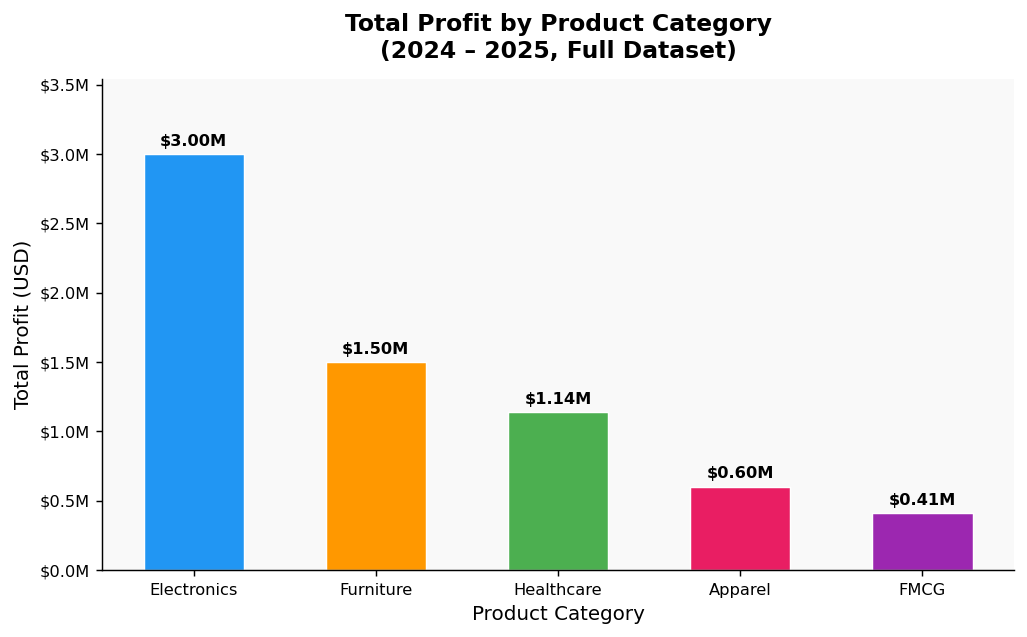

Chart saved → chart_2_1_vertical_bar.png


In [92]:
# ── Aggregate ────────────────────────────────────────────────────────────────
cat_profit = (
    df.groupby("Product Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    cat_profit["Product Category"],
    cat_profit["Profit"],
    color=PALETTE,
    width=0.55,
    edgecolor="white",
    linewidth=0.8,
)

# Value labels on top of each bar
for bar, val in zip(bars, cat_profit["Profit"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 40_000,
        f"${val/1e6:.2f}M",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

ax.set_title("Total Profit by Product Category\n(2024 – 2025, Full Dataset)", pad=12)
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Profit (USD)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))
ax.set_ylim(0, cat_profit["Profit"].max() * 1.18)
ax.set_facecolor("#f9f9f9")
plt.tight_layout()
plt.savefig("chart_2_1_vertical_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_1_vertical_bar.png")

#### 📌 Interpretation
- **Electronics** is the top profit generator at **\$3.00M** — accounting for **45.1%** of total profit (\$6.65M).
- **Furniture** comes second at **\$1.50M** (**22.6%**), followed by **Healthcare** at **\$1.14M** (**17.1%**).
- **Apparel (\$0.60M)** and **FMCG (\$0.41M)** earn the smallest shares (**9.0%** and **6.2%**).
- **Why this chart?** We have 5 short category names and one numeric measure (Profit).
  Bars sorted from tallest to shortest let the audience rank all categories in one glance.

### 2.2 Horizontal Bar Chart
**Definition:** Bars run **sideways from left to right**. The y-axis holds the category names
and the x-axis holds the numeric value.

**Why Horizontal?** We switch to horizontal bars when category labels are **long** or when there
are **many categories (> 8)**. Long labels on a vertical chart overlap and become unreadable.
Turning the chart sideways gives each label its own row, making everything legible.

**Data used:** Total **Orders** by **Customer Country** (27 countries, sorted by order count)

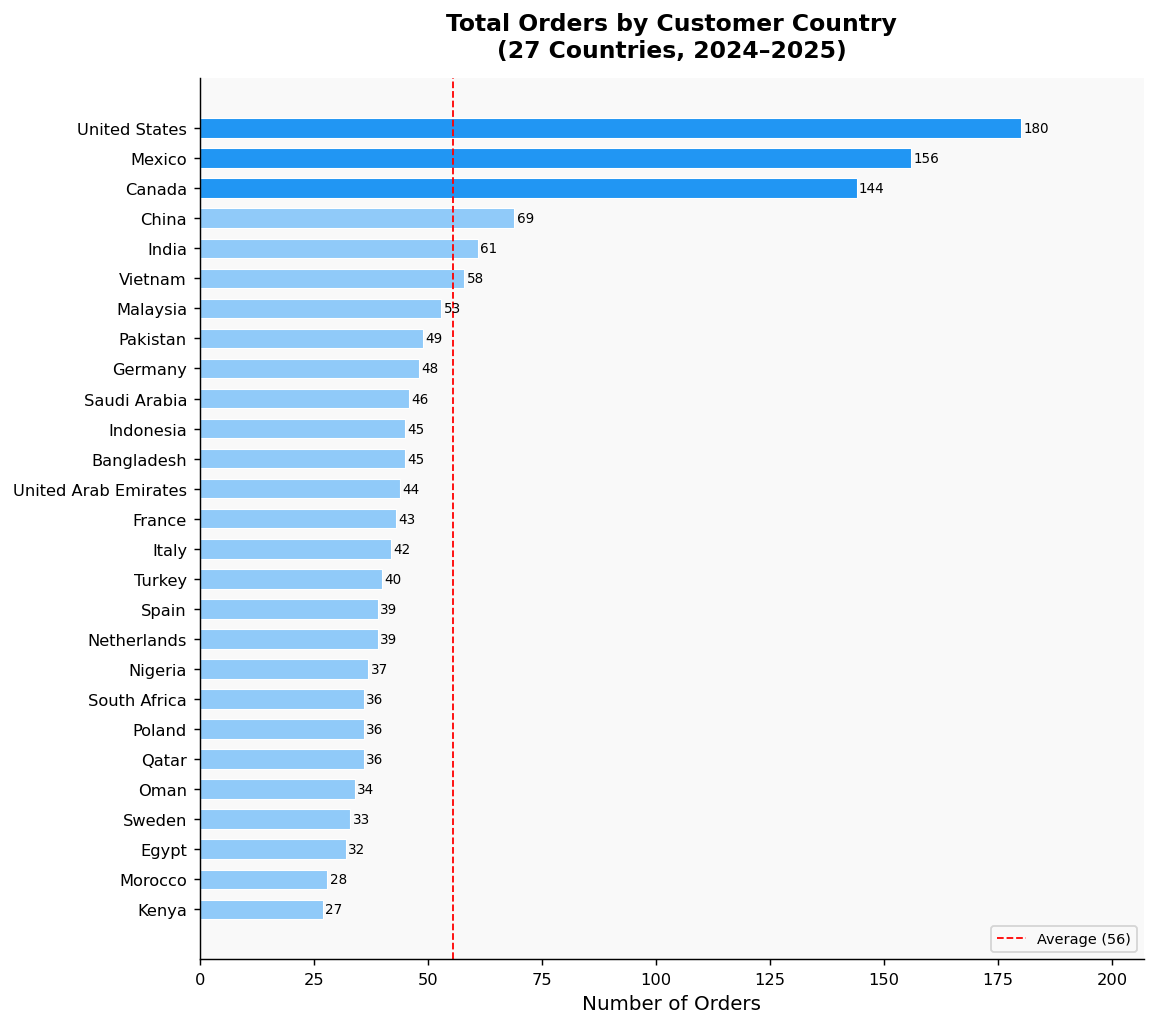

Chart saved → chart_2_2_horizontal_bar.png


In [93]:
# ── Aggregate ────────────────────────────────────────────────────────────────
country_orders = (
    df.groupby("Customer Country")["Order ID"]
    .count()
    .sort_values(ascending=True)       # ascending so largest is at the top
    .reset_index(name="Orders")
)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 8))

colors = ["#2196F3" if v >= 80 else "#90CAF9" for v in country_orders["Orders"]]

bars = ax.barh(
    country_orders["Customer Country"],
    country_orders["Orders"],
    color=colors,
    height=0.65,
    edgecolor="white",
    linewidth=0.6,
)

# Value labels at the end of each bar
for bar, val in zip(bars, country_orders["Orders"]):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center", fontsize=7.5
    )

ax.set_title("Total Orders by Customer Country\n(27 Countries, 2024–2025)", pad=12)
ax.set_xlabel("Number of Orders")
ax.set_ylabel("")
ax.set_xlim(0, country_orders["Orders"].max() * 1.15)
ax.axvline(country_orders["Orders"].mean(), color="red", linestyle="--",
           linewidth=1, label=f"Average ({country_orders['Orders'].mean():.0f})")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("chart_2_2_horizontal_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_2_horizontal_bar.png")

#### 📌 Interpretation
- **United States (180), Mexico (156), and Canada (144)** lead clearly (480 combined orders) — North America is our highest-volume market, followed by **China (69), India (61), and Vietnam (58)** above the **56-order average** (red dashed line).
- **Kenya (27), Morocco (28), Egypt (32), Sweden (33), and Oman (34)** have the fewest orders.
- This strong regional volume hierarchy aligns directly with the regional profit ranking shown in **Chart 2.4**.
- **Why this chart?** 27 country names would collide and overlap on a vertical x-axis.
  Turning the chart horizontal gives every country its own clean row.

### 2.3 Grouped (Clustered) Bar Charts — Twenty Variants
**Definition:** Multiple bars are placed **side-by-side** within each Transportation Mode.
Each colour represents a sub-category, allowing comparison across modes and within each mode.

The nine charts compare different measures using the same side-by-side grouped-bar technique:
- **2.3.1–2.3.9:** Different measures grouped by Product Category and Transportation Mode or Order Status.
- **2.3.10–2.3.20:** Regional and order-status comparisons. These use Customer Region or Supplier Region as the group axis, not Transportation Mode.

#### 2.3.1 Average Delivery Time (Days)
The bars compare average delivery time across Transportation Modes; each colour represents a Product Category.


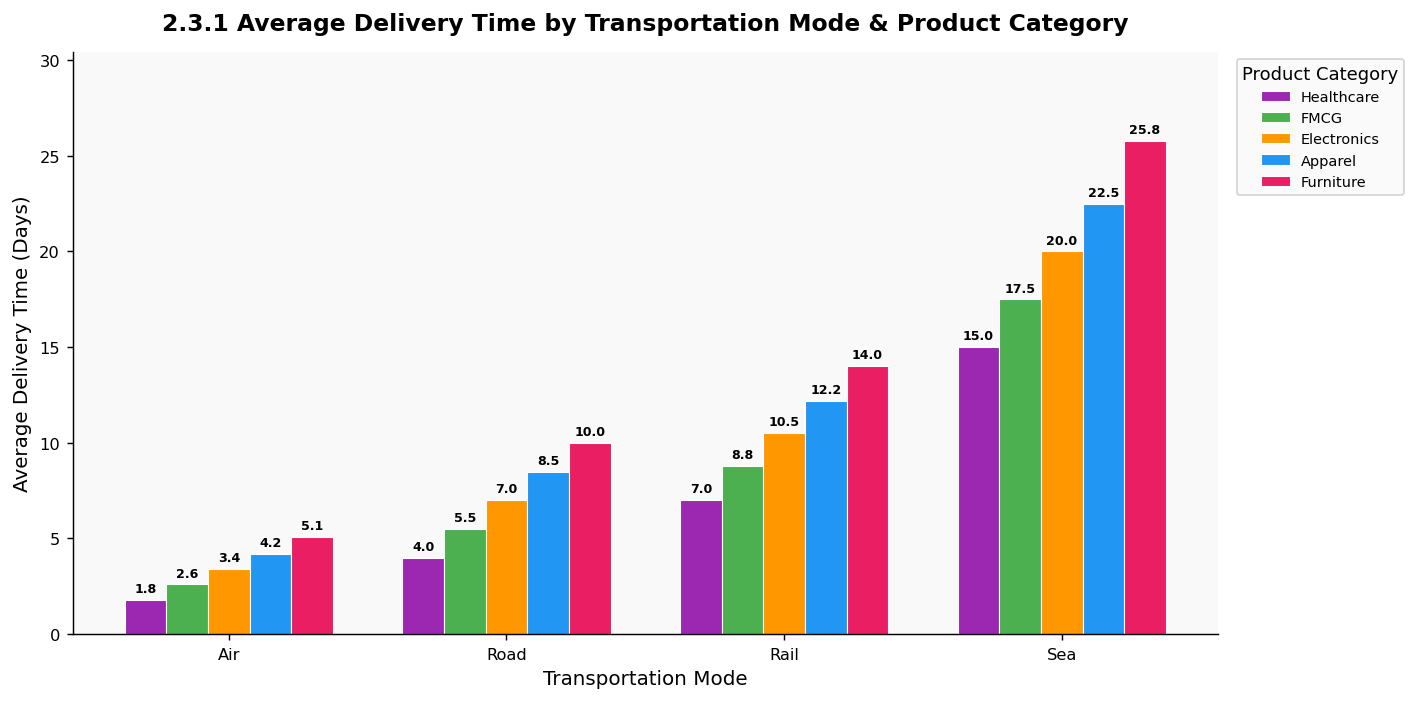

Chart saved -> chart_2_3_1_delivery_time.png


In [103]:
# ---- 2.3.1: Average Delivery Time ----
modes = ["Air", "Road", "Rail", "Sea"]
categories = ["Healthcare", "FMCG", "Electronics", "Apparel", "Furniture"]
cat_colors = {c: PALETTE[i] for i, c in enumerate(["Apparel", "Electronics", "FMCG", "Furniture", "Healthcare"])}
grp = df.groupby(["Transportation Mode", "Product Category"])["Delivery Time Days"].mean().round(1).reset_index()
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(categories)-1)/2 * width, (len(categories)-1)/2 * width, len(categories))

fig, ax = plt.subplots(figsize=(11, 5.5))
for cat, offset in zip(categories, offsets):
    vals = [
        grp.loc[(grp["Transportation Mode"] == m) &
                (grp["Product Category"] == cat), "Delivery Time Days"].mean()
        for m in modes
    ]
    bars = ax.bar(x + offset, vals, width, label=cat, color=cat_colors[cat],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.25,
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.1 Average Delivery Time by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Delivery Time (Days)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp["Delivery Time Days"].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_1_delivery_time.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_1_delivery_time.png")


#### 2.3.2 Average Profit
The bars compare average profit across Transportation Modes; each colour represents a Product Category.


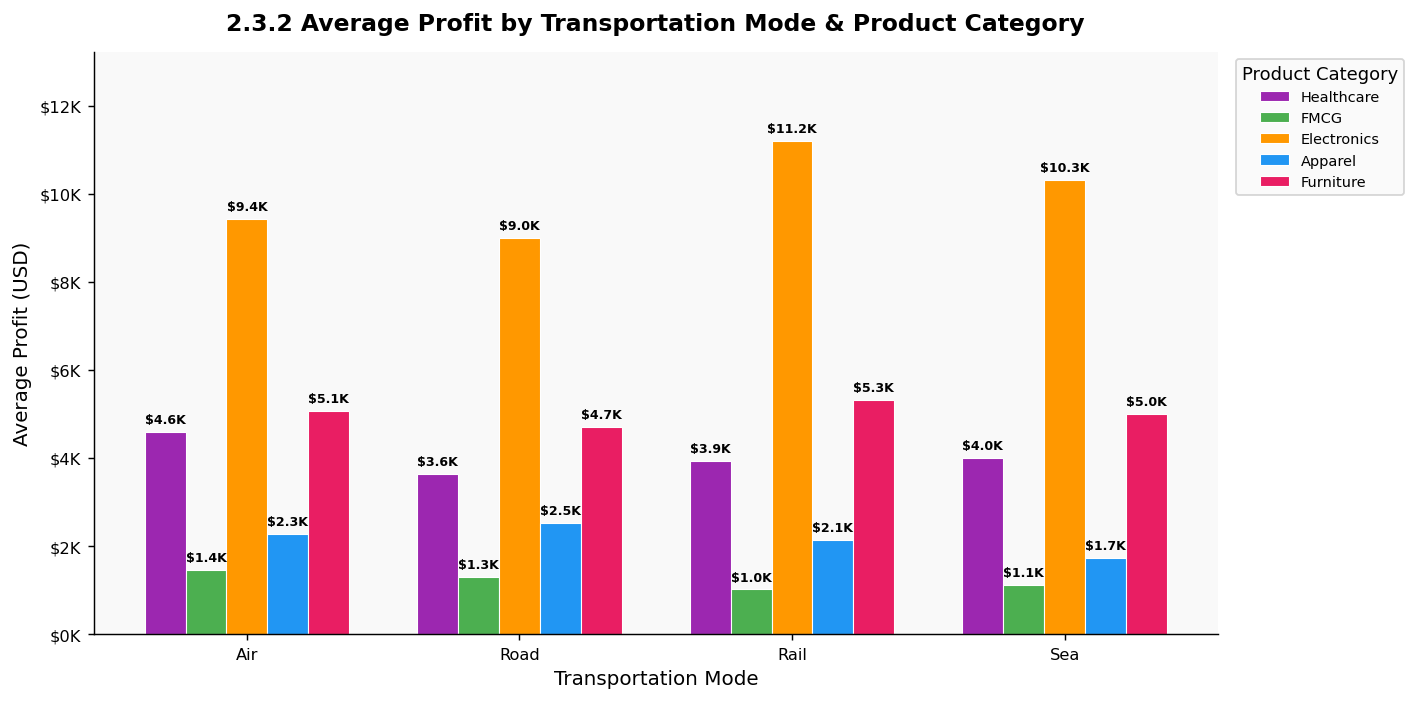

Chart saved -> chart_2_3_2_average_profit.png


In [104]:
# ---- 2.3.2: Average Profit ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Profit"].mean().round(0).reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
for cat, offset in zip(categories, offsets):
    vals = [
        grp.loc[(grp["Transportation Mode"] == m) &
                (grp["Product Category"] == cat), "Profit"].mean()
        for m in modes
    ]
    bars = ax.bar(x + offset, vals, width, label=cat, color=cat_colors[cat],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+grp["Profit"].max()*0.012,
                f"${val/1000:.1f}K", ha="center", va="bottom",
                fontsize=7, fontweight="bold")

ax.set_title("2.3.2 Average Profit by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Profit (USD)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp["Profit"].max()*1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${y/1000:.0f}K"))
plt.tight_layout()
plt.savefig("chart_2_3_2_average_profit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_2_average_profit.png")


#### 2.3.3 Order Count
The bars compare order volume across Transportation Modes; each colour represents a Product Category.


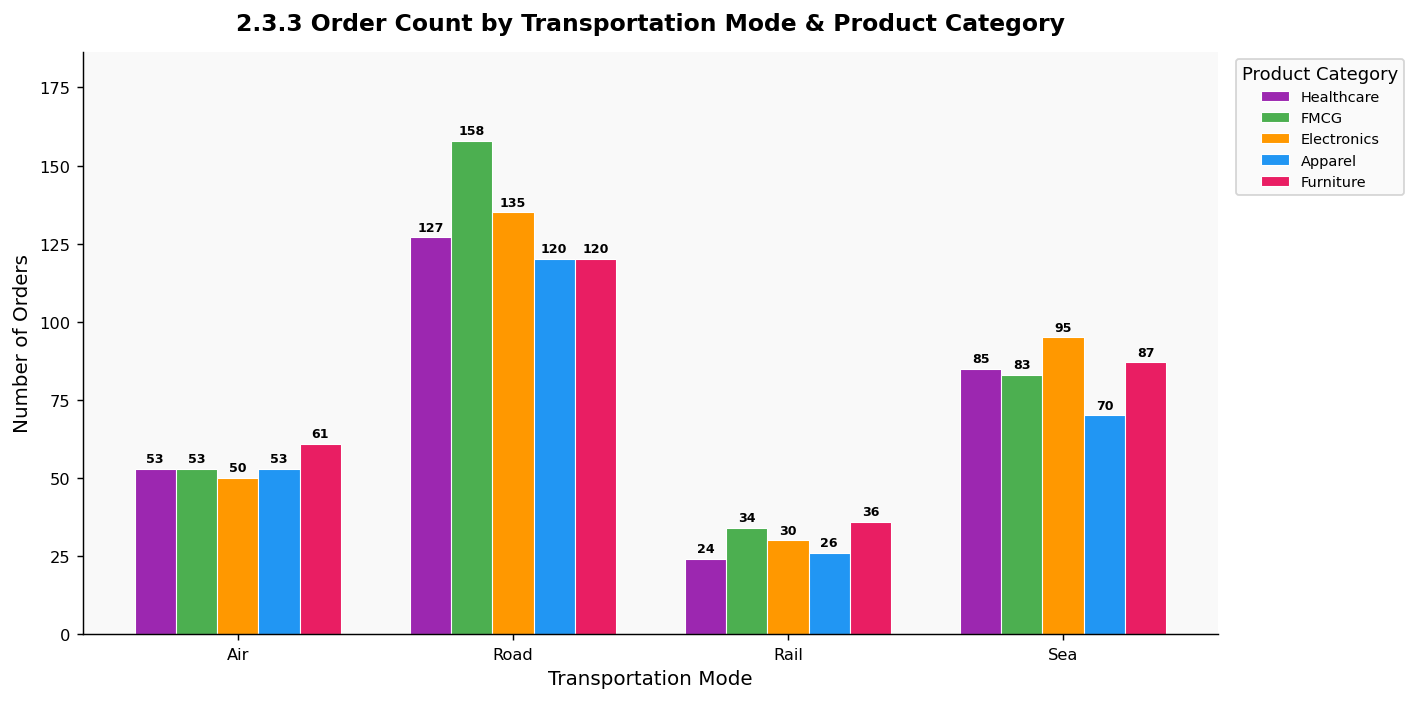

Chart saved -> chart_2_3_3_order_count.png


In [105]:
# ---- 2.3.3: Order Count ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Order ID"].count().reset_index(name="Order Count")

fig, ax = plt.subplots(figsize=(11, 5.5))
for cat, offset in zip(categories, offsets):
    vals = [
        grp.loc[(grp["Transportation Mode"] == m) &
                (grp["Product Category"] == cat), "Order Count"].sum()
        for m in modes
    ]
    bars = ax.bar(x + offset, vals, width, label=cat, color=cat_colors[cat],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.2,
                f"{int(val)}", ha="center", va="bottom",
                fontsize=7, fontweight="bold")

ax.set_title("2.3.3 Order Count by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Number of Orders")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp["Order Count"].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_3_order_count.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_3_order_count.png")


#### Interpretation
- **2.3.1:** Compare average delivery speed; shorter bars indicate faster delivery.
- **2.3.2:** Compare average profitability; taller bars indicate higher average profit per order.
- **2.3.3:** Compare order volume; taller bars indicate more orders using that category and mode combination.
- The side-by-side format keeps the same comparison: differences **across transportation modes** and **within each mode** remain easy to inspect.


#### 2.3.4 Average Order Quantity
Compare the average number of units per order for each mode and product category.


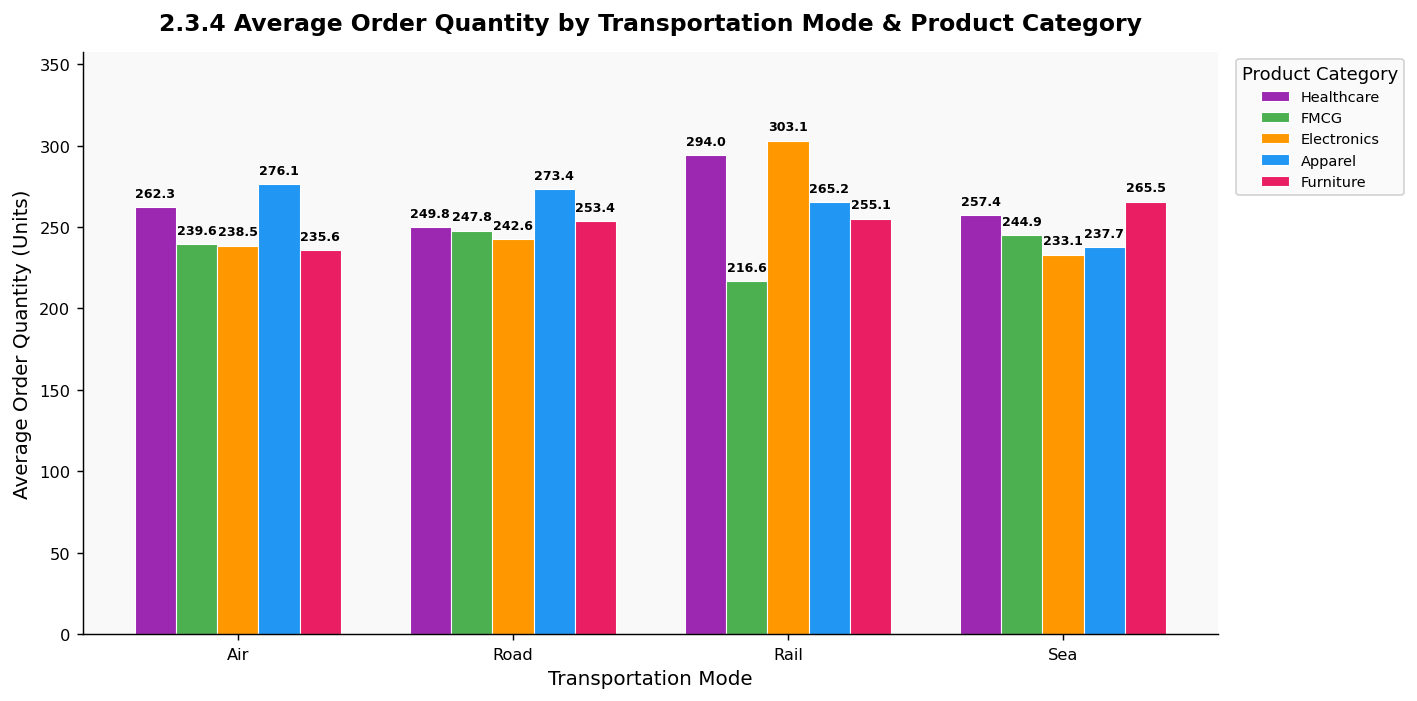

Chart saved -> chart_2_3_4_avg_order_quantity.png


In [106]:
# ---- 2.3.4: Average Order Quantity ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Order Quantity"].mean().reset_index(name="Average Order Quantity")
subgroups = categories
group_name = "Product Category"
colors = cat_colors
metric_column = "Average Order Quantity"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(matching.iloc[0] if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 0.1),
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.4 Average Order Quantity by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Order Quantity (Units)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_4_avg_order_quantity.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_4_avg_order_quantity.png")


#### 2.3.5 Average Unit Price
Compare average per-unit prices across transportation modes and product categories.


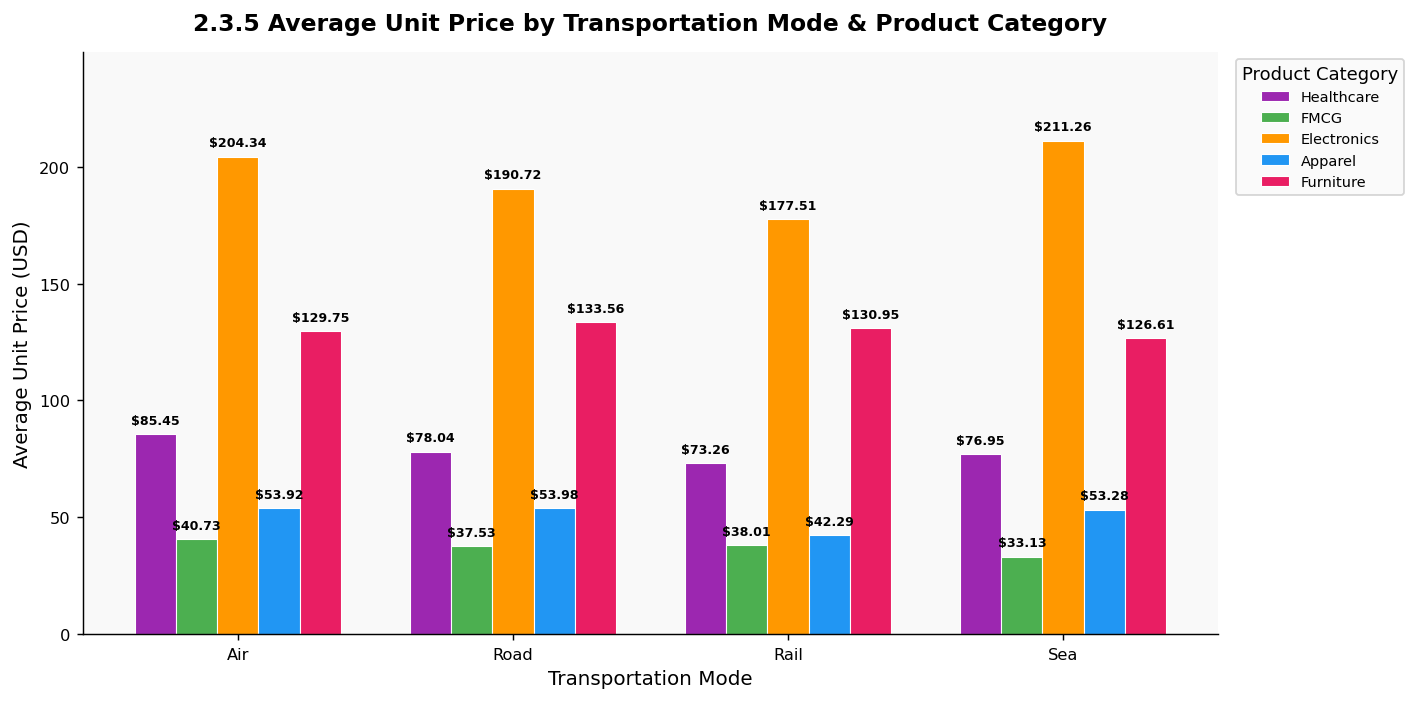

Chart saved -> chart_2_3_5_avg_unit_price.png


In [107]:
# ---- 2.3.5: Average Unit Price ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Unit Price"].mean().reset_index(name="Average Unit Price")
subgroups = categories
group_name = "Product Category"
colors = cat_colors
metric_column = "Average Unit Price"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(matching.iloc[0] if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 0.1),
                f"${val:,.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.5 Average Unit Price by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Unit Price (USD)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_5_avg_unit_price.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_5_avg_unit_price.png")


#### 2.3.6 Total Cost
Compare cumulative order costs for each mode and product category.


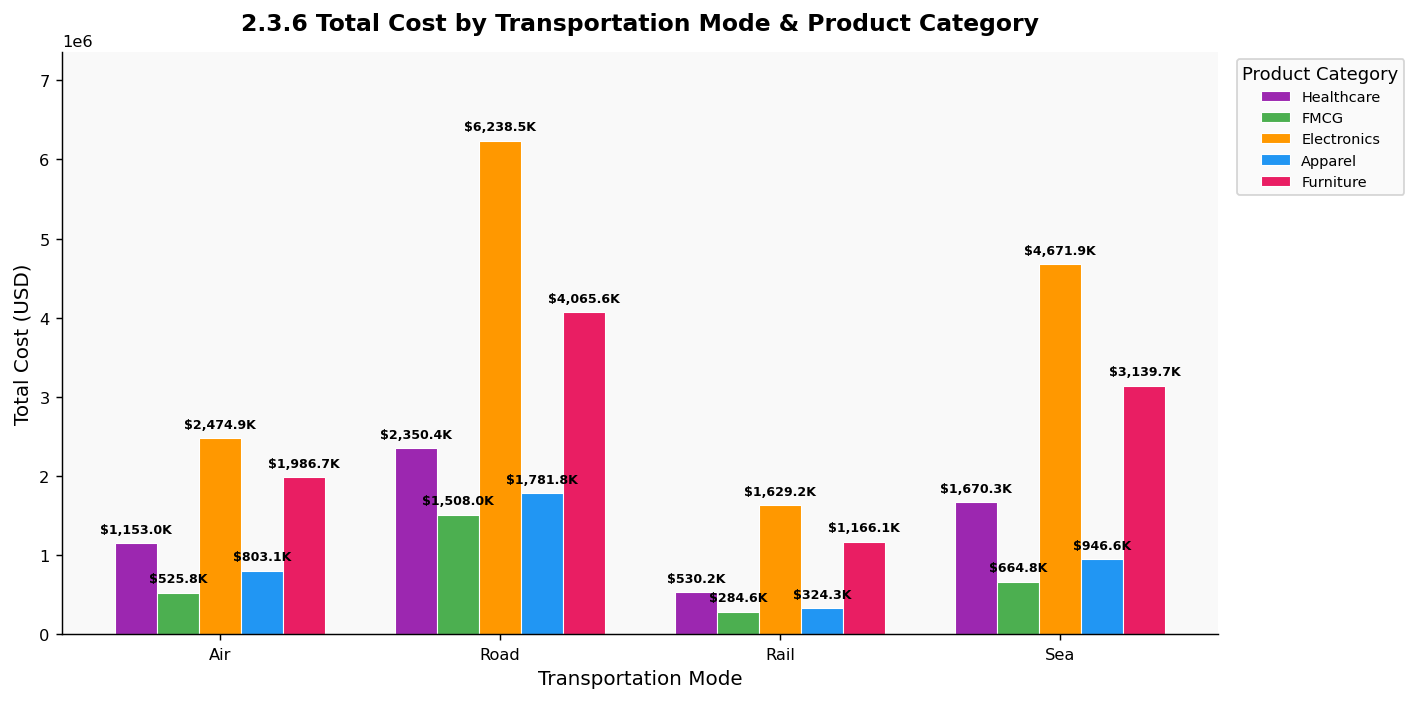

Chart saved -> chart_2_3_6_total_cost.png


In [108]:
# ---- 2.3.6: Total Cost ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Total Cost"].sum().reset_index(name="Total Cost")
subgroups = categories
group_name = "Product Category"
colors = cat_colors
metric_column = "Total Cost"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(matching.iloc[0] if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 0.1),
                f"${val/1000:,.1f}K", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.6 Total Cost by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Total Cost (USD)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_6_total_cost.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_6_total_cost.png")


#### 2.3.7 Average Shipping Cost
Compare the average shipping charge associated with each mode and product category.


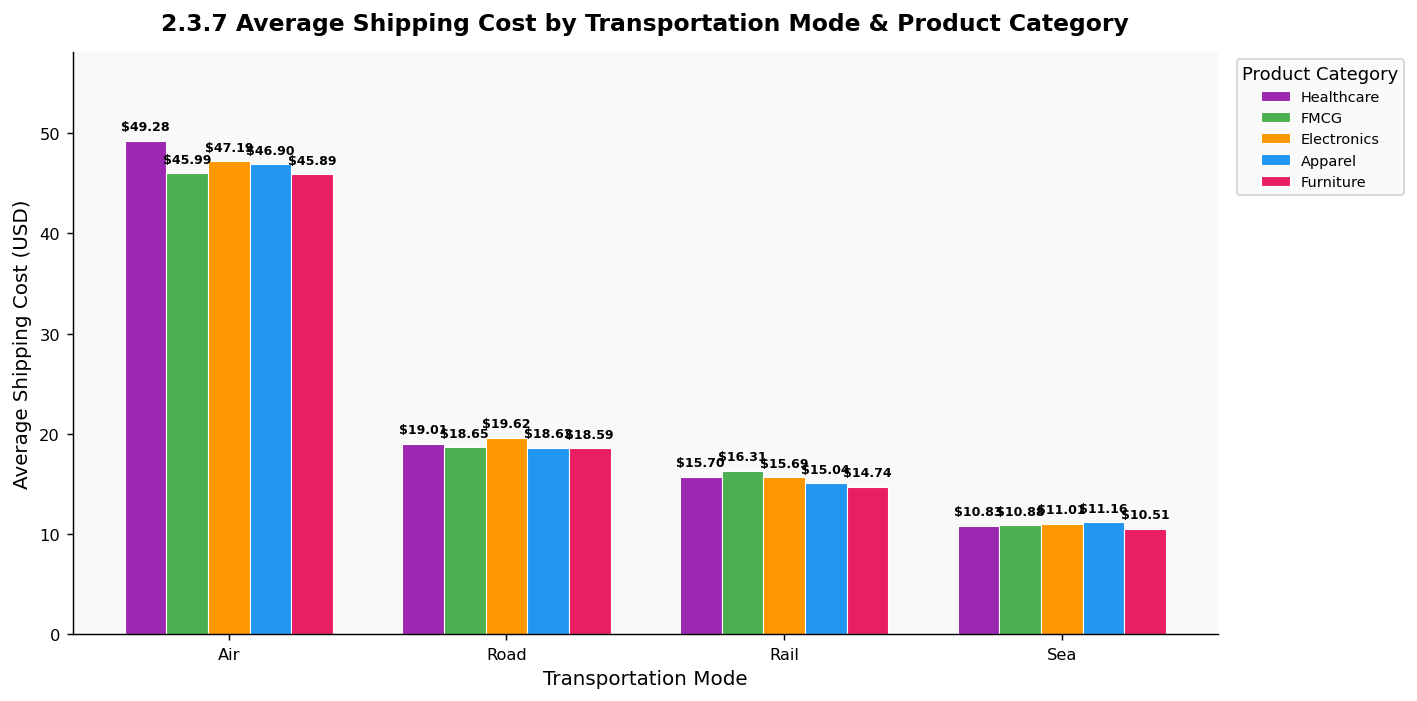

Chart saved -> chart_2_3_7_avg_shipping_cost.png


In [109]:
# ---- 2.3.7: Average Shipping Cost ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Shipping Cost"].mean().reset_index(name="Average Shipping Cost")
subgroups = categories
group_name = "Product Category"
colors = cat_colors
metric_column = "Average Shipping Cost"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(matching.iloc[0] if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 0.1),
                f"${val:.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.7 Average Shipping Cost by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Shipping Cost (USD)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_7_avg_shipping_cost.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_7_avg_shipping_cost.png")


#### 2.3.8 Average Inventory Level
Compare the mean inventory level recorded for orders in each mode and product category.


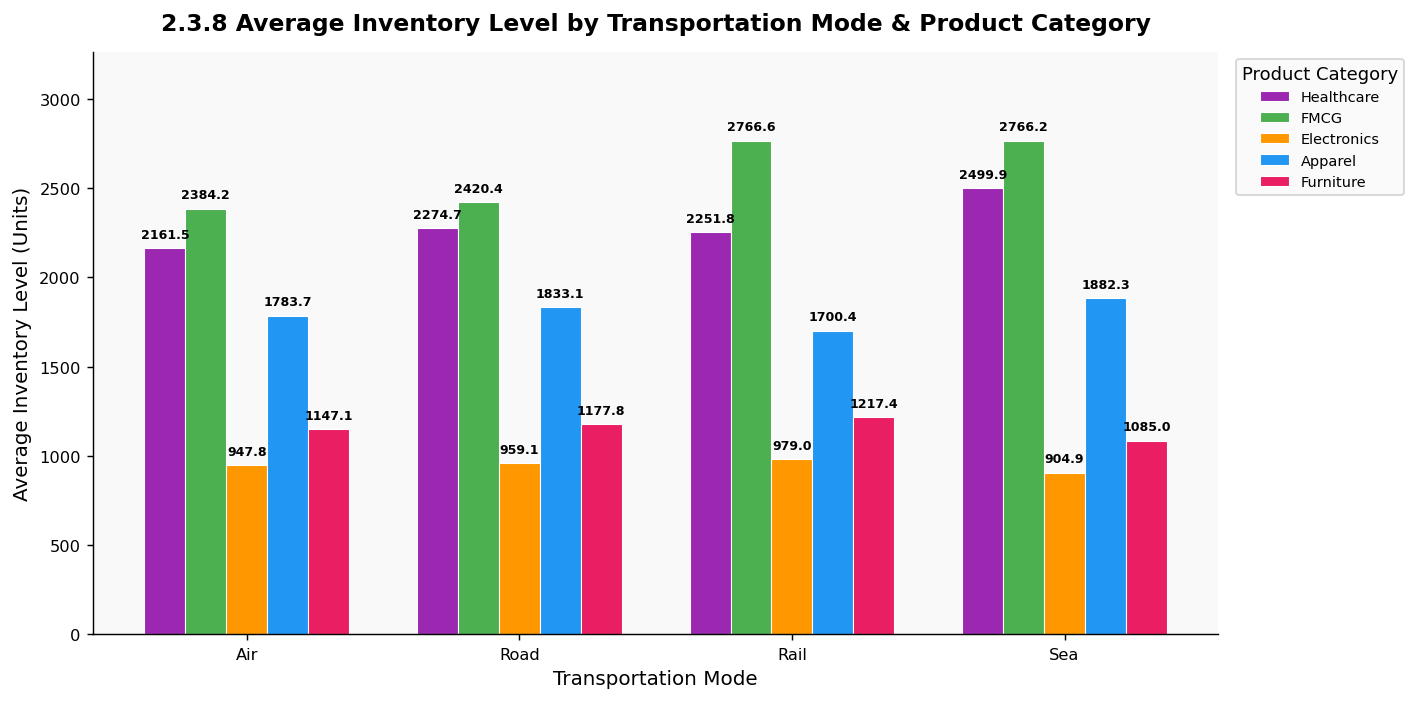

Chart saved -> chart_2_3_8_avg_inventory.png


In [110]:
# ---- 2.3.8: Average Inventory Level ----
grp = df.groupby(["Transportation Mode", "Product Category"])["Inventory Level"].mean().reset_index(name="Average Inventory Level")
subgroups = categories
group_name = "Product Category"
colors = cat_colors
metric_column = "Average Inventory Level"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(matching.iloc[0] if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 0.1),
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.8 Average Inventory Level by Transportation Mode & Product Category", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Average Inventory Level (Units)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_8_avg_inventory.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_8_avg_inventory.png")


#### 2.3.9 Order Status Count
Compare order volume by transportation mode, with each bar colour identifying an order status.


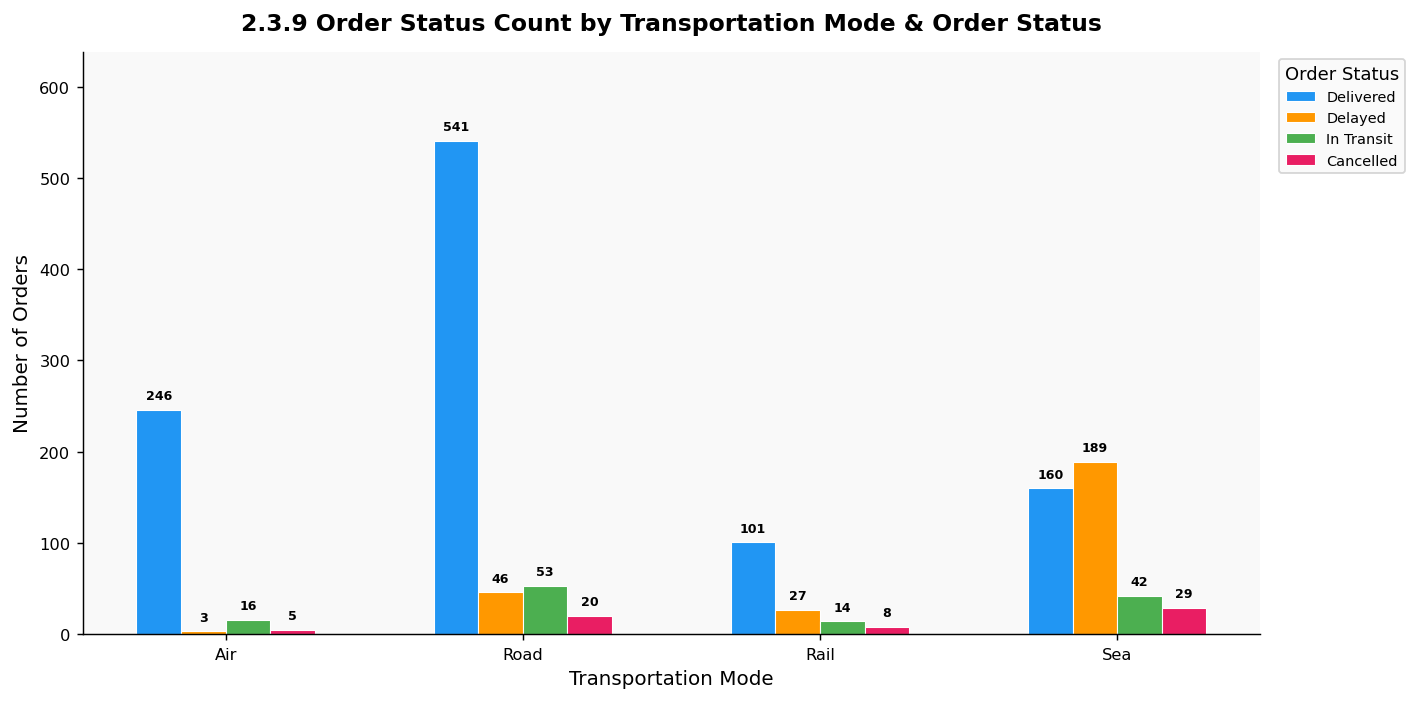

Chart saved -> chart_2_3_9_order_status_count.png


In [111]:
# ---- 2.3.9: Order Status Count ----
grp = df.groupby(["Transportation Mode", "Order Status"])["Order ID"].count().reset_index(name="Order Count")
subgroups = ["Delivered", "Delayed", "In Transit", "Cancelled"]
group_name = "Order Status"
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
metric_column = "Order Count"
x = np.arange(len(modes))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for mode in modes:
        matching = grp.loc[
            (grp["Transportation Mode"] == mode) &
            (grp[group_name] == subgroup), metric_column
        ]
        vals.append(int(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max() * 0.015, 1),
                f"{int(val)}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.9 Order Status Count by Transportation Mode & Order Status", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Number of Orders")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Order Status", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig("chart_2_3_9_order_status_count.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_9_order_status_count.png")


#### 2.3.10 Average Delivery Time by Customer Region
Compare average delivery time for each product category across customer regions.


In [ ]:
# ---- 2.3.10: Average Delivery Time by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Delivery Time'
grp = df.groupby([group_column, subgroup_column])['Delivery Time Days'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.10 Average Delivery Time by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Average Delivery Time (Days)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_10_delivery_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_10_delivery_region.png")


#### 2.3.11 Total Profit by Customer Region
Compare cumulative profit by product category across customer regions.


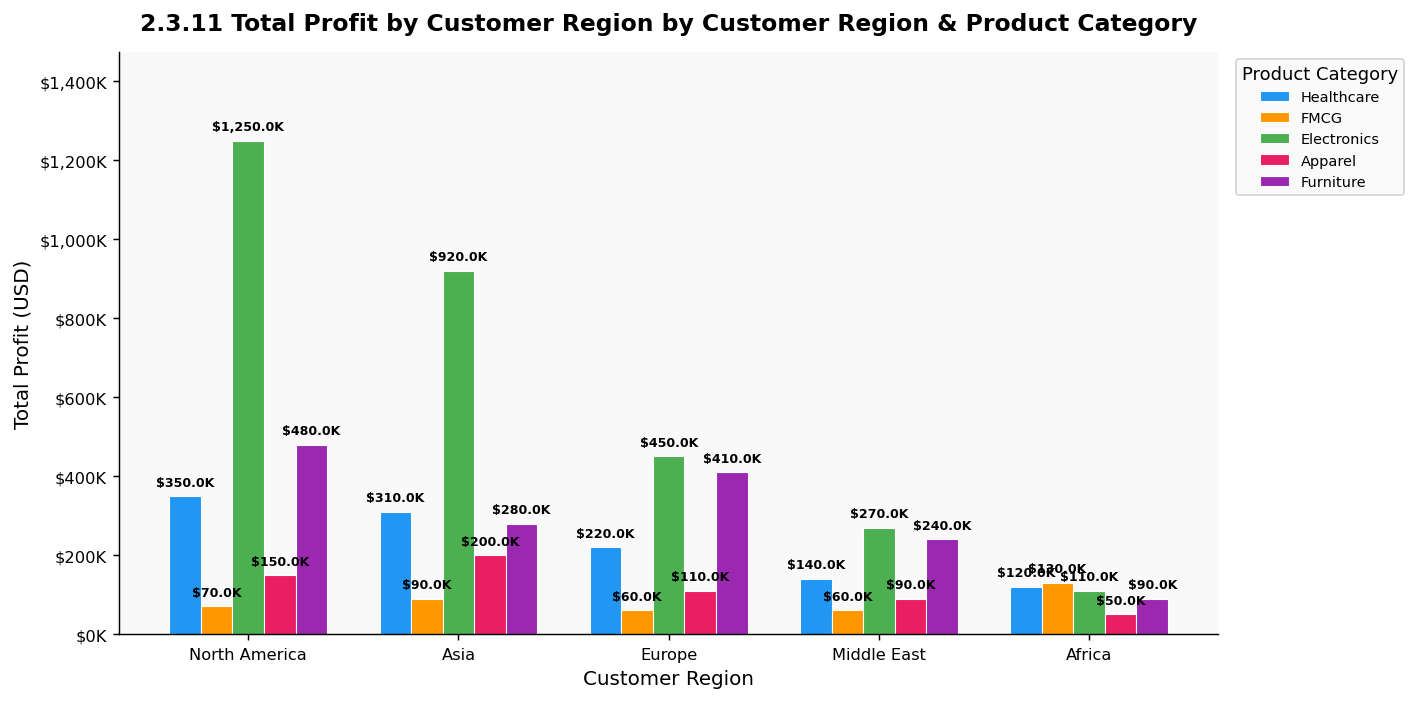

Chart saved -> chart_2_3_11_profit_region.png


In [112]:
# ---- 2.3.11: Total Profit by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Total Profit'
grp = df.groupby([group_column, subgroup_column])['Profit'].sum().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"${val/1000:,.1f}K", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.11 Total Profit by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Total Profit (USD)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${y/1000:,.0f}K"))
plt.tight_layout()
plt.savefig('chart_2_3_11_profit_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_11_profit_region.png")


#### 2.3.12 Average Order Quantity by Customer Region
Compare the average units per order for product categories across customer regions.


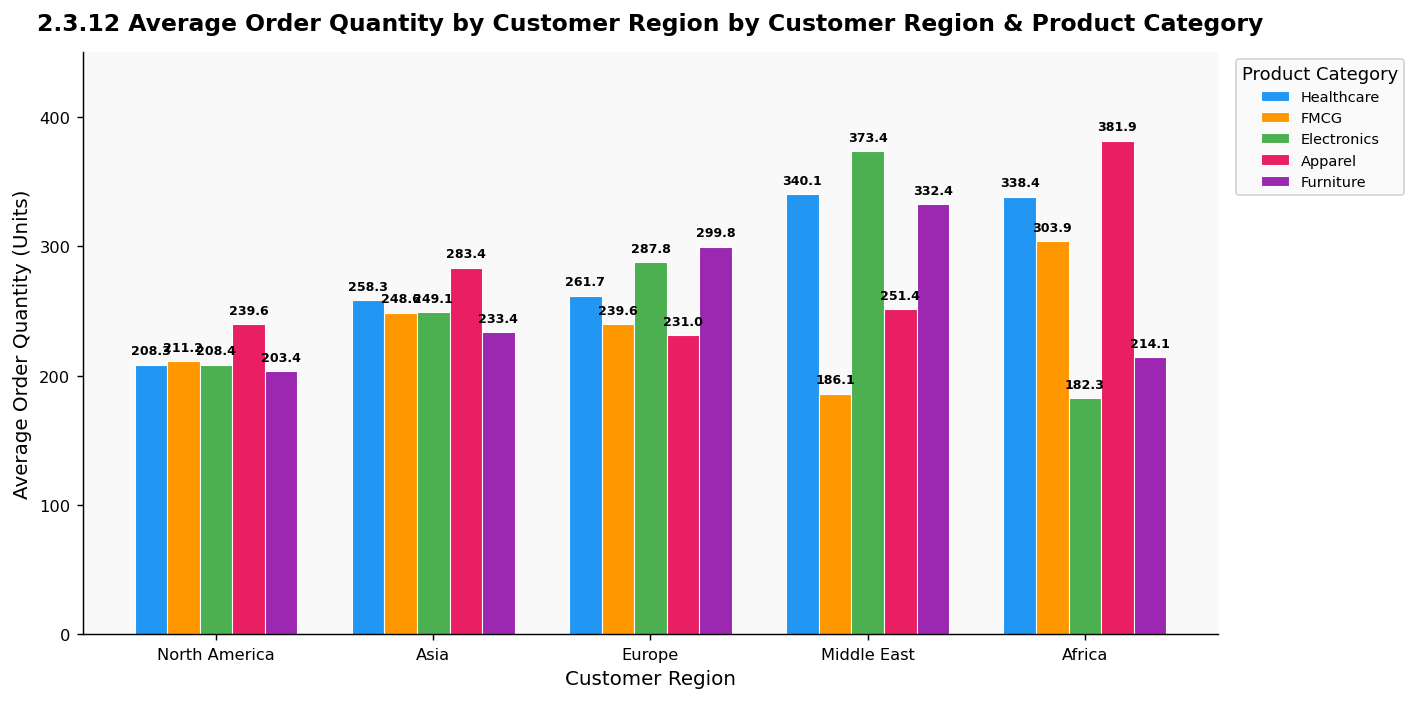

Chart saved -> chart_2_3_12_quantity_region.png


In [113]:
# ---- 2.3.12: Average Order Quantity by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Order Quantity'
grp = df.groupby([group_column, subgroup_column])['Order Quantity'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.12 Average Order Quantity by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Average Order Quantity (Units)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_12_quantity_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_12_quantity_region.png")


#### 2.3.13 Average Unit Price by Customer Region
Compare product-category average unit prices across customer regions.


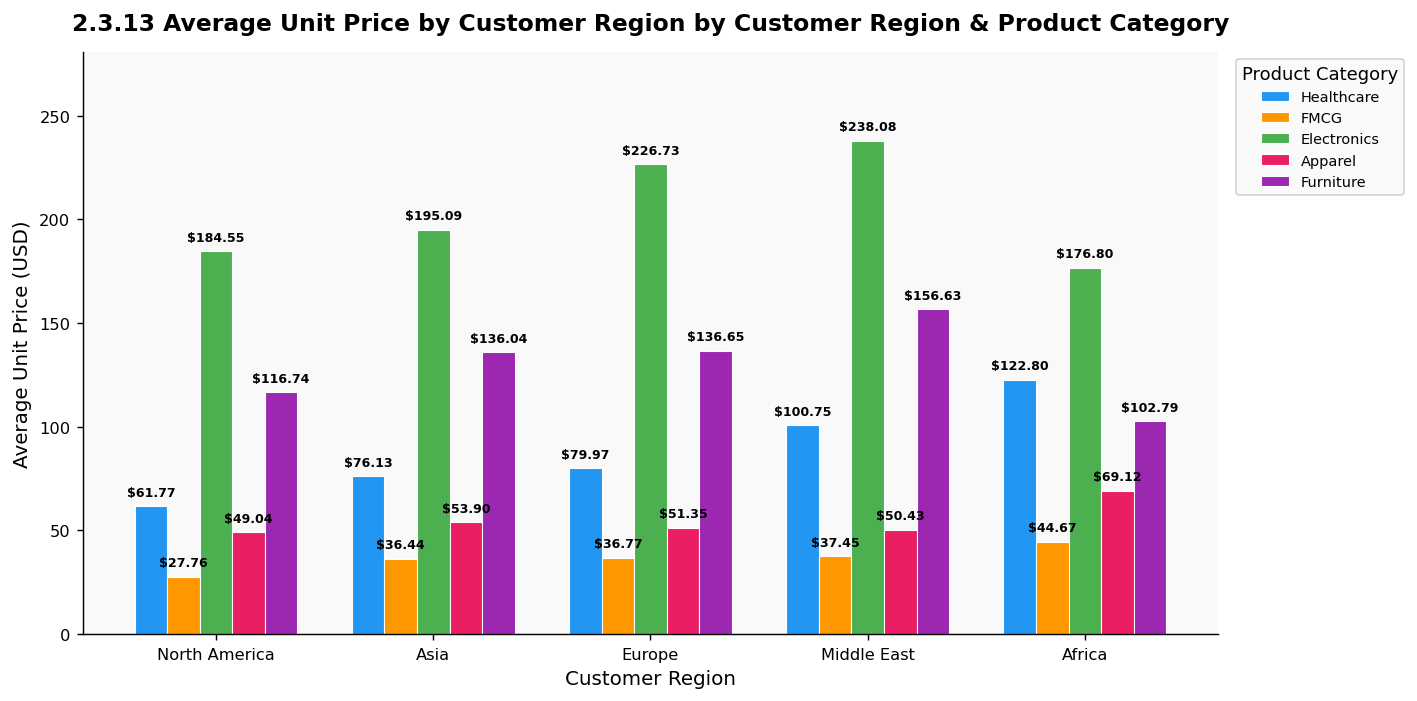

Chart saved -> chart_2_3_13_unit_price_region.png


In [114]:
# ---- 2.3.13: Average Unit Price by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Unit Price'
grp = df.groupby([group_column, subgroup_column])['Unit Price'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"${val:,.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.13 Average Unit Price by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Average Unit Price (USD)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_13_unit_price_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_13_unit_price_region.png")


#### 2.3.14 Total Cost by Customer Region
Compare total order costs for product categories across customer regions.


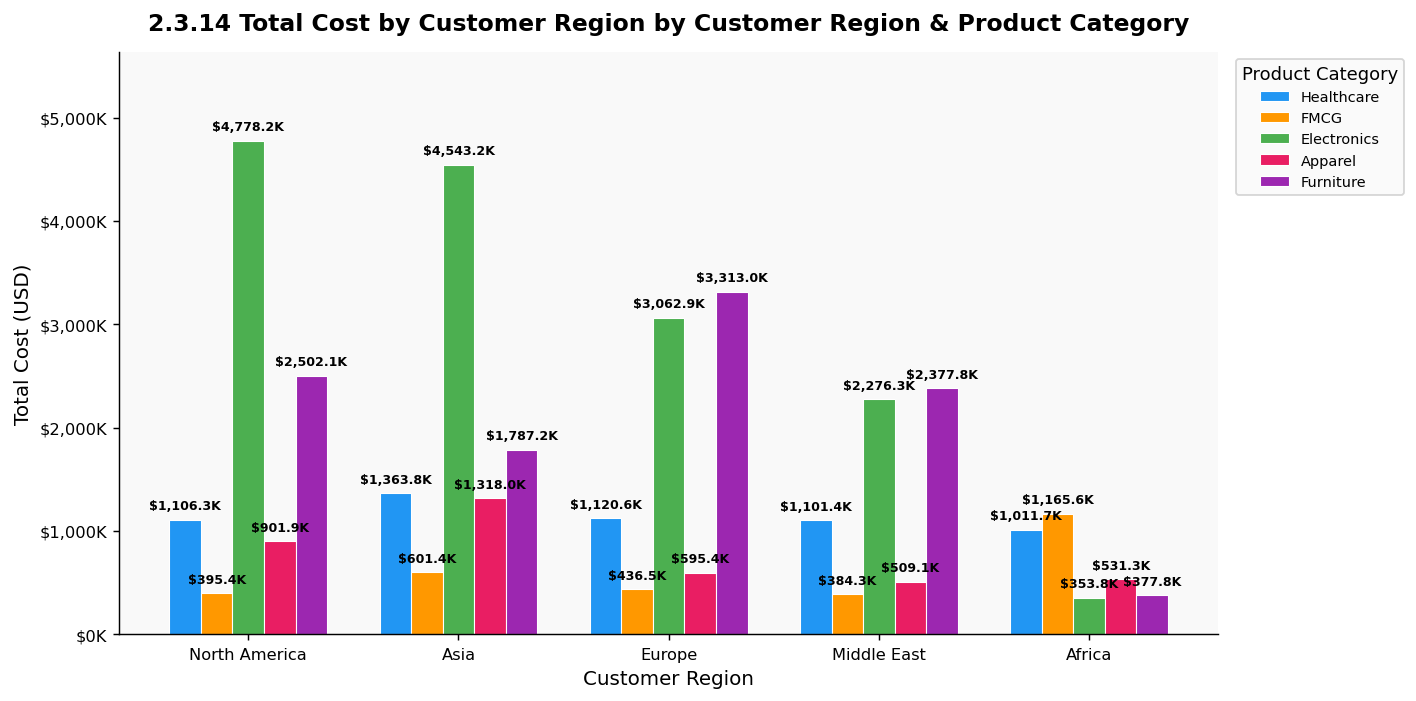

Chart saved -> chart_2_3_14_total_cost_region.png


In [115]:
# ---- 2.3.14: Total Cost by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Total Cost'
grp = df.groupby([group_column, subgroup_column])['Total Cost'].sum().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"${val/1000:,.1f}K", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.14 Total Cost by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Total Cost (USD)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${y/1000:,.0f}K"))
plt.tight_layout()
plt.savefig('chart_2_3_14_total_cost_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_14_total_cost_region.png")


#### 2.3.15 Average Shipping Cost by Customer Region
Compare average shipping cost for product categories across customer regions.


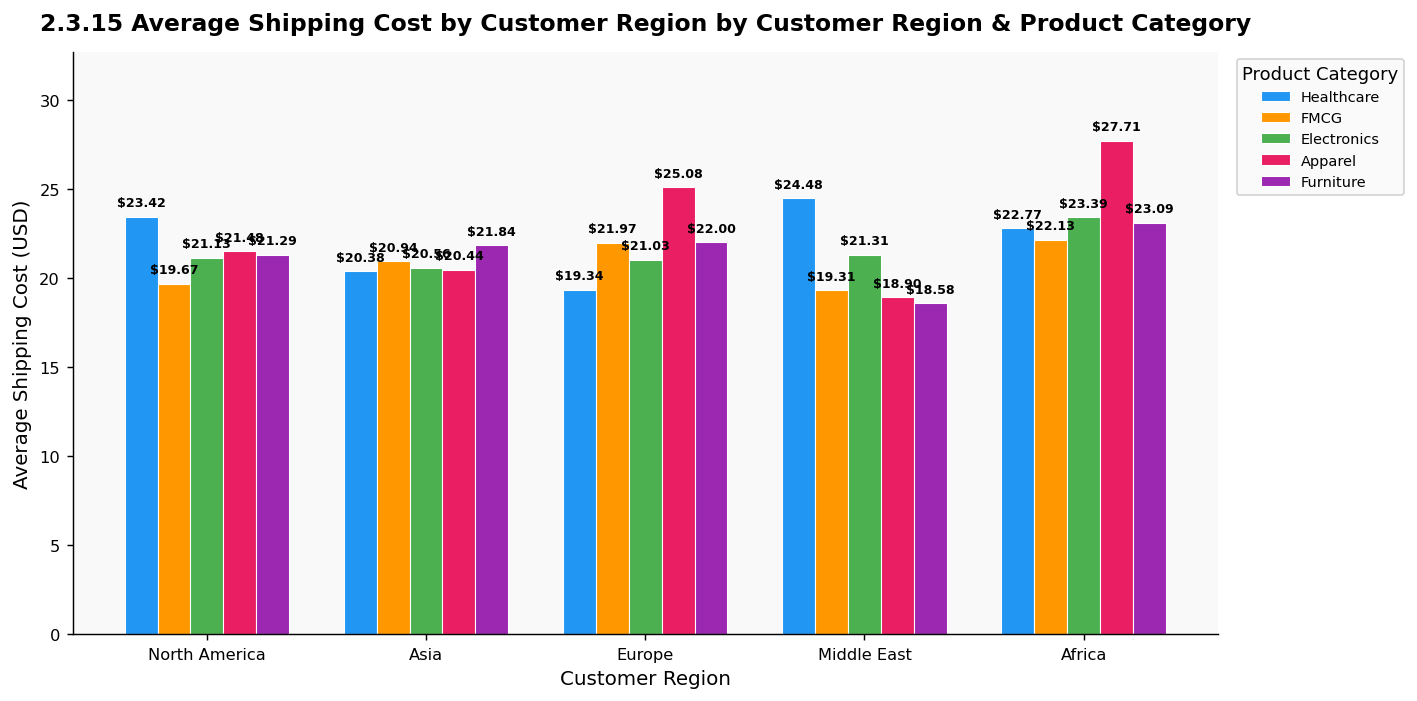

Chart saved -> chart_2_3_15_shipping_region.png


In [116]:
# ---- 2.3.15: Average Shipping Cost by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Shipping Cost'
grp = df.groupby([group_column, subgroup_column])['Shipping Cost'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"${val:.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.15 Average Shipping Cost by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Average Shipping Cost (USD)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_15_shipping_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_15_shipping_region.png")


#### 2.3.16 Average Inventory Level by Customer Region
Compare mean recorded inventory levels for product categories across customer regions.


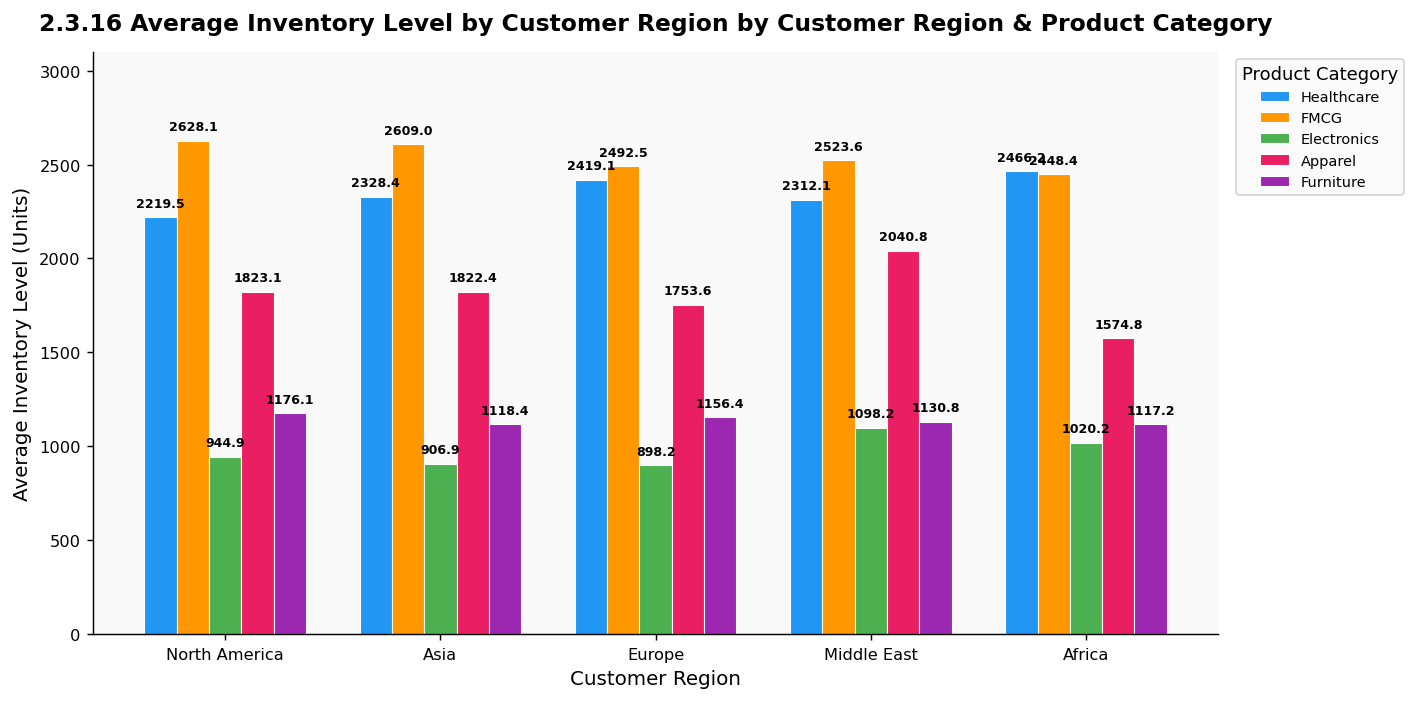

Chart saved -> chart_2_3_16_inventory_region.png


In [117]:
# ---- 2.3.16: Average Inventory Level by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Inventory Level'
grp = df.groupby([group_column, subgroup_column])['Inventory Level'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{val:.1f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.16 Average Inventory Level by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Average Inventory Level (Units)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_16_inventory_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_16_inventory_region.png")


#### 2.3.17 Order Count by Customer Region
Compare order volume for each product category across customer regions.


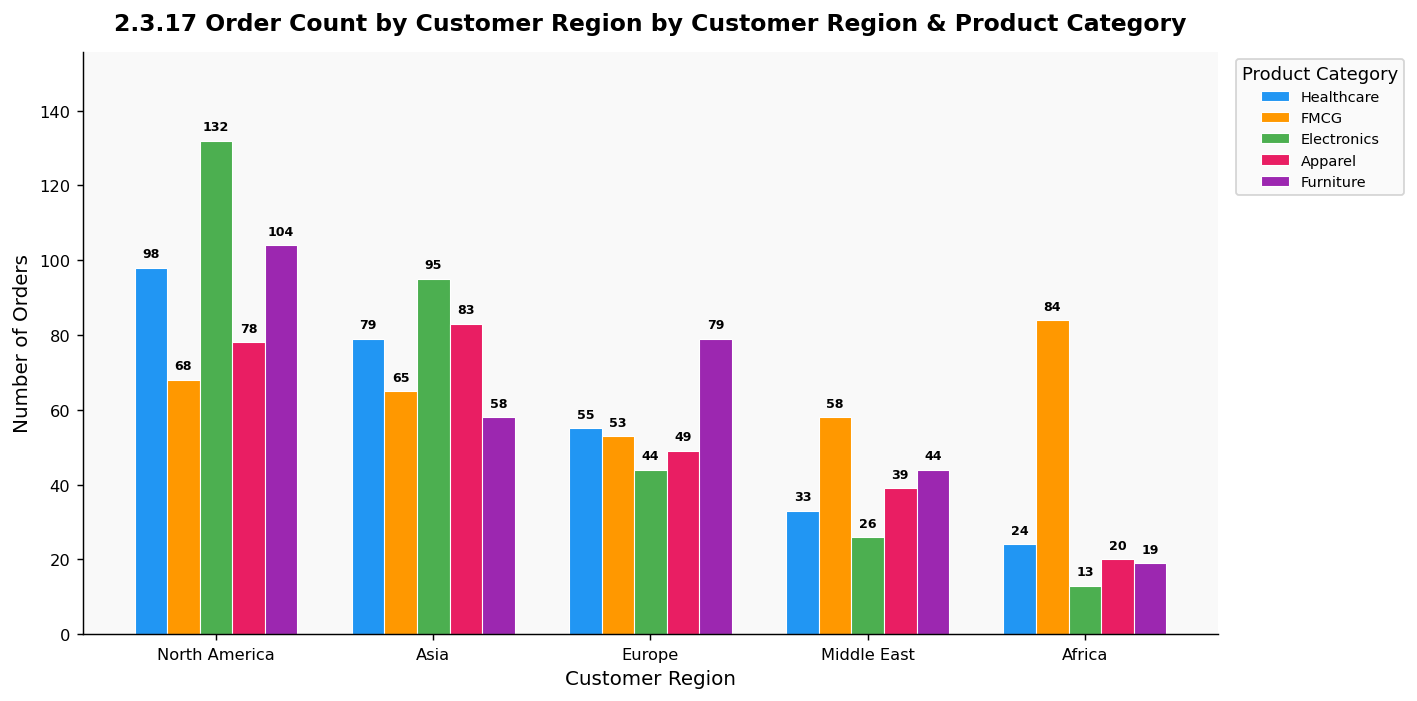

Chart saved -> chart_2_3_17_order_count_region.png


In [118]:
# ---- 2.3.17: Order Count by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Order Count'
grp = df.groupby([group_column, subgroup_column])['Order ID'].count().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{int(val)}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.17 Order Count by Customer Region by Customer Region & Product Category", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Number of Orders')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_17_order_count_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_17_order_count_region.png")


#### 2.3.18 Order Status Count by Customer Region
Compare order statuses across customer regions using order counts.


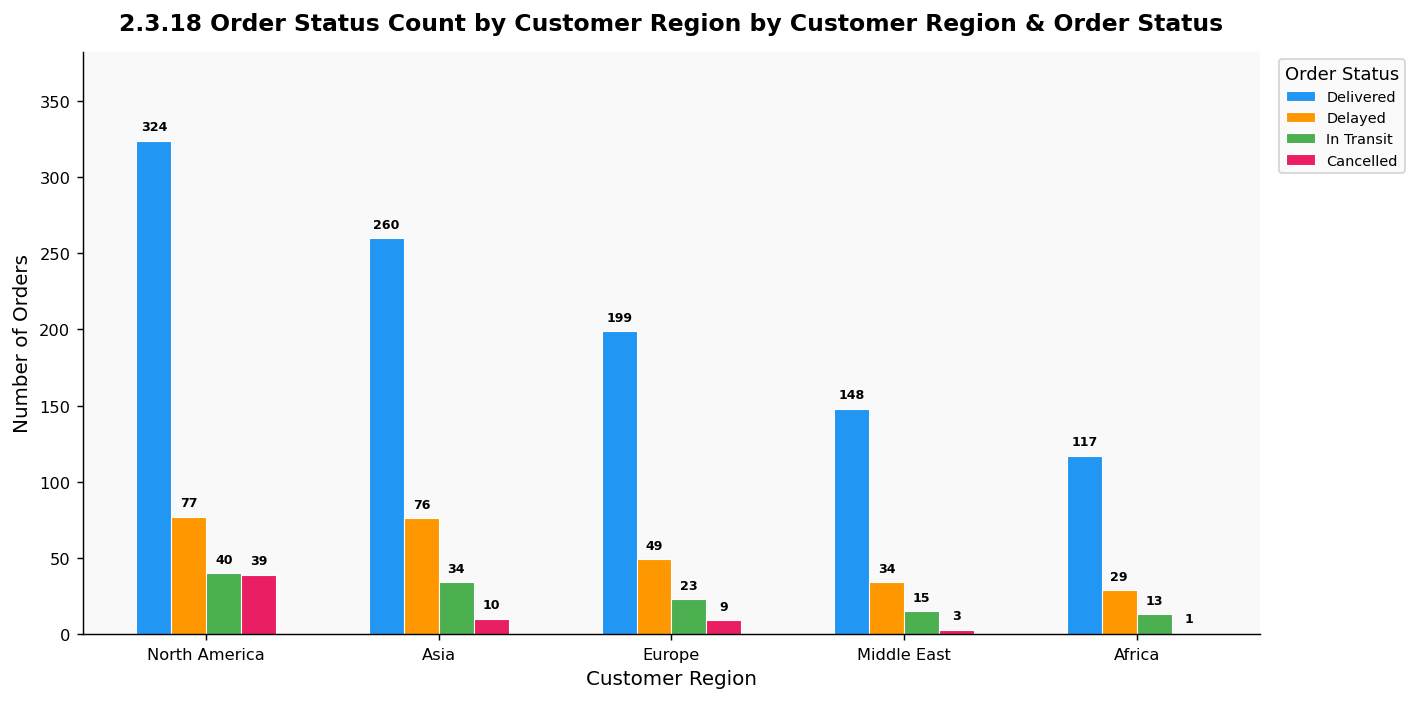

Chart saved -> chart_2_3_18_status_region.png


In [119]:
# ---- 2.3.18: Order Status Count by Customer Region ----
group_column = 'Customer Region'
subgroup_column = 'Order Status'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Delivered', 'Delayed', 'In Transit', 'Cancelled']
metric_column = 'Order Count'
grp = df.groupby([group_column, subgroup_column])['Order ID'].count().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{int(val)}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.18 Order Status Count by Customer Region by Customer Region & Order Status", pad=12)
ax.set_xlabel('Customer Region')
ax.set_ylabel('Number of Orders')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Order Status', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_18_status_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_18_status_region.png")


#### 2.3.19 Average Profit by Supplier Region
Compare average profit for product categories across supplier regions.


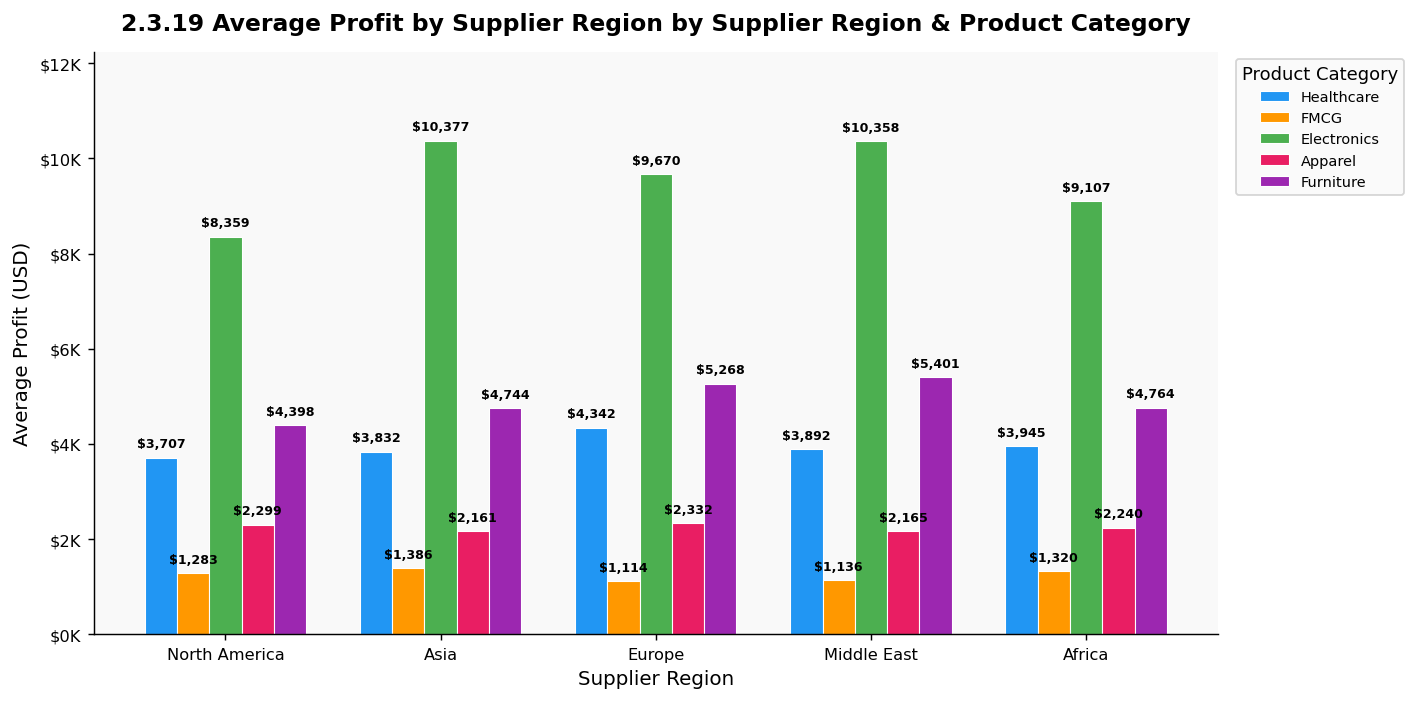

Chart saved -> chart_2_3_19_profit_supplier_region.png


In [120]:
# ---- 2.3.19: Average Profit by Supplier Region ----
group_column = 'Supplier Region'
subgroup_column = 'Product Category'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Healthcare', 'FMCG', 'Electronics', 'Apparel', 'Furniture']
metric_column = 'Average Profit'
grp = df.groupby([group_column, subgroup_column])['Profit'].mean().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"${val:,.0f}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.19 Average Profit by Supplier Region by Supplier Region & Product Category", pad=12)
ax.set_xlabel('Supplier Region')
ax.set_ylabel('Average Profit (USD)')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f"${y/1000:,.0f}K"))
plt.tight_layout()
plt.savefig('chart_2_3_19_profit_supplier_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_19_profit_supplier_region.png")


#### 2.3.20 Order Status Count by Supplier Region
Compare order statuses across supplier regions using order counts.


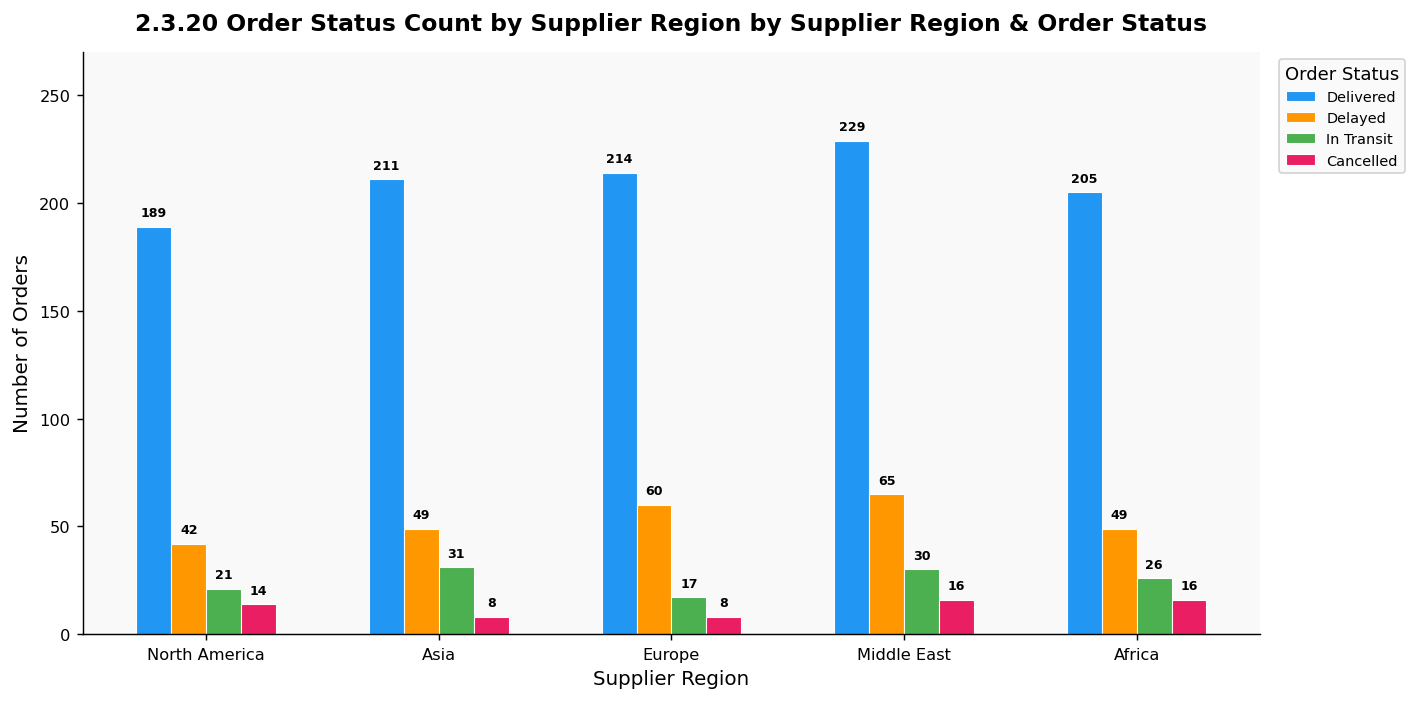

Chart saved -> chart_2_3_20_status_supplier_region.png


In [121]:
# ---- 2.3.20: Order Status Count by Supplier Region ----
group_column = 'Supplier Region'
subgroup_column = 'Order Status'
groups = ['North America', 'Asia', 'Europe', 'Middle East', 'Africa']
subgroups = ['Delivered', 'Delayed', 'In Transit', 'Cancelled']
metric_column = 'Order Count'
grp = df.groupby([group_column, subgroup_column])['Order ID'].count().reset_index(name=metric_column)
colors = {name: PALETTE[i % len(PALETTE)] for i, name in enumerate(subgroups)}
x = np.arange(len(groups))
width = 0.15
offsets = np.linspace(-(len(subgroups)-1)/2 * width, (len(subgroups)-1)/2 * width, len(subgroups))

fig, ax = plt.subplots(figsize=(11, 5.5))
for subgroup, offset in zip(subgroups, offsets):
    vals = []
    for group in groups:
        matching = grp.loc[
            (grp[group_column] == group) & (grp[subgroup_column] == subgroup),
            metric_column
        ]
        vals.append(float(matching.iloc[0]) if not matching.empty else 0)
    bars = ax.bar(x + offset, vals, width, label=subgroup, color=colors[subgroup],
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(grp[metric_column].max()*0.015, 0.1),
                f"{int(val)}", ha="center", va="bottom", fontsize=7, fontweight="bold")

ax.set_title("2.3.20 Order Status Count by Supplier Region by Supplier Region & Order Status", pad=12)
ax.set_xlabel('Supplier Region')
ax.set_ylabel('Number of Orders')
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(title='Order Status', bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp[metric_column].max()*1.18)
plt.tight_layout()
plt.savefig('chart_2_3_20_status_supplier_region.png', dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved -> chart_2_3_20_status_supplier_region.png")


### 2.4 Stacked Bar Chart
**Definition:** Bars are split into coloured segments that are **stacked on top of each other**.
The total bar height shows the overall value; each colour segment shows one sub-category's contribution.

**Why Stacked?** When you want to see **both the total AND the breakdown** in one chart.
Unlike grouped bars, stacked bars emphasise the total. The trade-off is that comparing
individual segments is harder (segments don't all start from zero).

**Data used:** Total **Profit** by **Customer Region** (5 regions), broken down by
**Product Category** (5 categories)

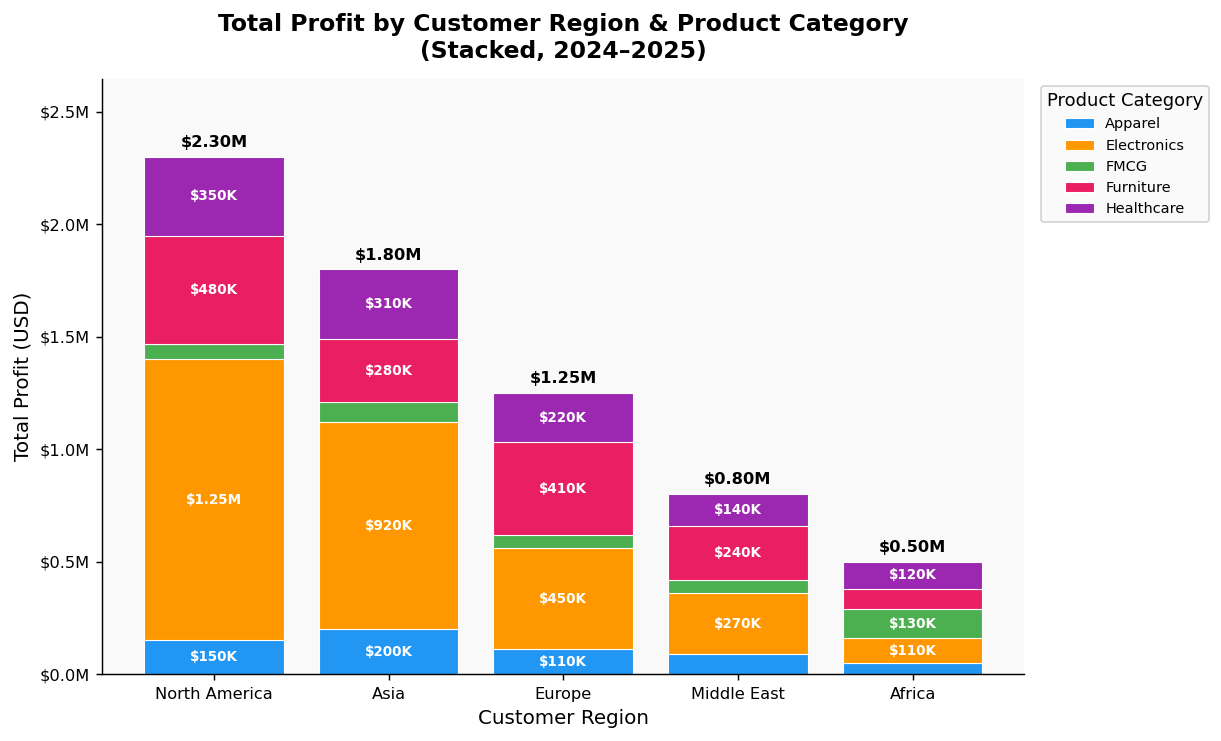

Chart saved → chart_2_4_stacked_bar.png


In [95]:
# ── Aggregate ────────────────────────────────────────────────────────────────
stk = (
    df.groupby(["Customer Region", "Product Category"])["Profit"]
    .sum()
    .unstack("Product Category")
    .fillna(0)
)
# Sort regions by total profit descending
stk = stk.loc[stk.sum(axis=1).sort_values(ascending=False).index]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9.5, 5.8))

bottom = np.zeros(len(stk))
for cat, color in zip(stk.columns, PALETTE):
    bars = ax.bar(stk.index, stk[cat], bottom=bottom,
                  label=cat, color=color, edgecolor="white", linewidth=0.6)
    # Only label segments tall enough to fit text cleanly inside
    for bar, val in zip(bars, stk[cat]):
        if val >= 105_000:
            lbl = f"${val/1e6:.2f}M" if val >= 1_000_000 else f"${val/1e3:.0f}K"
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    lbl,
                    ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    bottom += stk[cat].values

# Total label on top of each bar
for i, (region, total) in enumerate(stk.sum(axis=1).items()):
    ax.text(i, total + 30_000, f"${total/1e6:.2f}M",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Total Profit by Customer Region & Product Category\n(Stacked, 2024–2025)",
             pad=12)
ax.set_xlabel("Customer Region")
ax.set_ylabel("Total Profit (USD)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, stk.sum(axis=1).max() * 1.15)
plt.tight_layout()
plt.savefig("chart_2_4_stacked_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_4_stacked_bar.png")

#### 📌 Interpretation
- Total profit steps cleanly across five distinct regional tiers: **North America (\$2.30M)** → **Asia (\$1.80M)** → **Europe (\$1.25M)** → **Middle East (\$0.80M)** → **Africa (\$0.50M)**.
- **Distinct category mixes reveal each region's commercial profile:**
  - **North America (\$2.30M)** and **Asia (\$1.80M)** are tech-led powerhouses driven by **Electronics** (**\$1.25M / 54.3%** and **\$920K / 51.1%**), with Asia also leading global **Apparel (\$200K)**.
  - **Europe (\$1.25M)** shows a mature lifestyle mix where **Furniture (\$410K / 32.8%)** nearly matches **Electronics (\$450K / 36.0%)**, while **Middle East (\$0.80M)** balances **Electronics (\$270K)** and **Furniture (\$240K)**.
  - **Africa (\$0.50M)** stands out as an essentials-focused market where **FMCG (\$130K / 26.0%)** and **Healthcare (\$120K / 24.0%)** account for **50.0%** of regional profit.
- **Why this chart?** It answers two questions together: (1) how total profit ranks across regions,
  and (2) how each region's internal category mix differs by market demand.

### 2.5 100% Stacked Bar Chart
**Definition:** Every bar is stretched to exactly **100%**. The coloured segments now show
**proportions (percentages)** rather than raw values. All bars are the same height.

**Why 100% Stacked?** When you want to compare the **share or mix** of sub-categories
across groups — and the total size of each group does NOT matter. It makes proportional
differences very clear even when one group has 4× more orders than another.

**Data used:** **Order Status** share (Delivered / In Transit / Delayed / Cancelled)
across each **Transportation Mode** — showing which mode is most reliable.

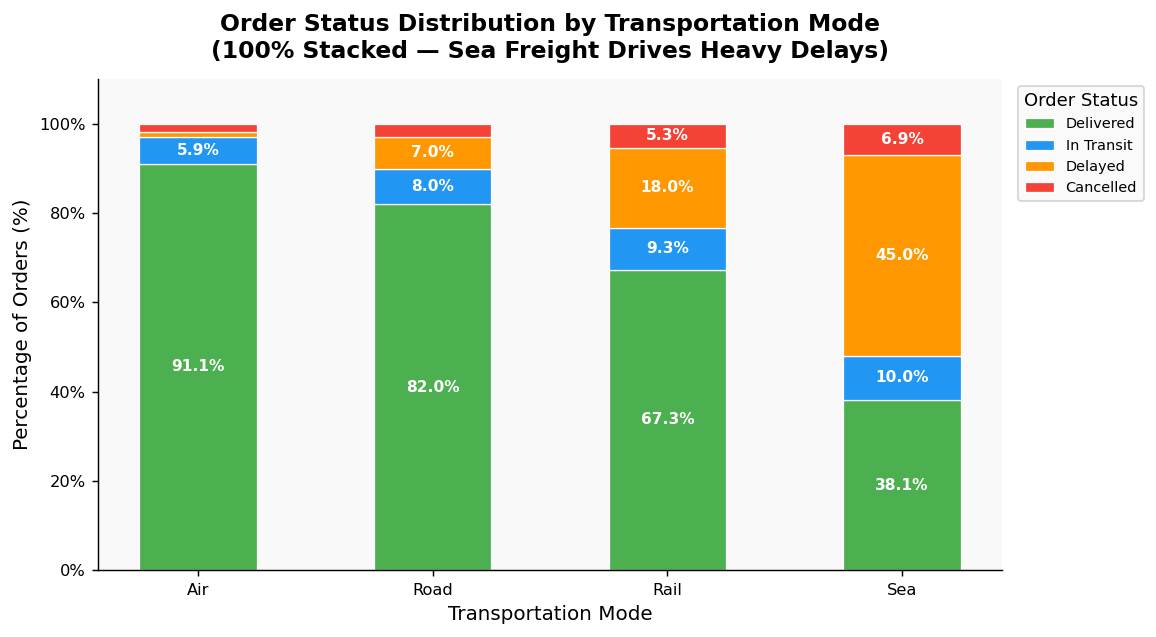

Chart saved → chart_2_5_100pct_stacked_bar.png


In [96]:
# ── Aggregate ────────────────────────────────────────────────────────────────
pct = (
    df.groupby(["Transportation Mode", "Order Status"])["Order ID"]
    .count()
    .unstack("Order Status")
    .fillna(0)
)
pct_norm = pct.div(pct.sum(axis=1), axis=0) * 100   # convert to %

# Fix colour order for status (green = good, red = bad)
status_order  = ["Delivered", "In Transit", "Delayed", "Cancelled"]
status_colors = ["#4CAF50", "#2196F3", "#FF9800", "#F44336"]
pct_norm = pct_norm[status_order]

# Sort rows by "Delivered %" descending (most reliable first)
pct_norm = pct_norm.sort_values("Delivered", ascending=False)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

bottom = np.zeros(len(pct_norm))
for status, color in zip(status_order, status_colors):
    vals = pct_norm[status].values
    bars = ax.bar(pct_norm.index, vals, bottom=bottom,
                  label=status, color=color, edgecolor="white", linewidth=0.7, width=0.5)
    for bar, val in zip(bars, vals):
        if val >= 3.5:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    f"{val:.1f}%",
                    ha="center", va="center", fontsize=8.5,
                    color="white", fontweight="bold")
    bottom += vals

ax.set_title("Order Status Distribution by Transportation Mode\n"
             "(100% Stacked — Sea Freight Drives Heavy Delays)", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Percentage of Orders (%)")
ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.legend(title="Order Status", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("chart_2_5_100pct_stacked_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_5_100pct_stacked_bar.png")

#### 📌 Interpretation
- **Air** is the most reliable mode: **91.1% Delivered** and only **1.1% Delayed** (1.9% Cancelled).
- **Road** performs well at **82.0% Delivered** with **7.0% Delayed**, while **Rail** rises to **18.0% Delayed** (**67.3% Delivered**).
- **Sea is the major delay bottleneck:** **45.0% of Sea orders are Delayed** (plus **6.9% Cancelled**), leaving only **38.1% Delivered**!
- **Why this chart?** Road carries **660** orders while Rail carries only **150**. Comparing raw counts
  would make Road look worse just because it has higher volume. Stretching every bar to 100% puts all
  4 modes on an equal scale — immediately exposing **Sea** as the problem channel.

### 2.6 Waterfall Chart
**Definition:** A Waterfall chart shows how a **starting value changes step-by-step** to reach
a final value. Green bars are increases; red bars are decreases; blue bars are totals.
The chart looks like stepping stones — each bar "floats" at the level where the previous one ended.

**Why Waterfall?** When you want to explain **what drove a big change** between two totals.
It answers the question *"We started at X and ended at Y — which categories pulled us down and which pushed us up?"*
Unlike a simple bar chart (which only shows the start and end), a Waterfall shows every positive and negative driver.

**Data used:** Total **Profit** change from **2024 to 2025** broken down by **Product Category**.

In [97]:
# ── Aggregate ────────────────────────────────────────────────────────────────
yearly = (
    df.groupby(["Order Year", "Product Category"])["Profit"]
    .sum()
    .unstack("Order Year")
    .fillna(0)
)
yearly.columns = [2024, 2025]
yearly["Change"] = yearly[2025] - yearly[2024]
yearly = yearly.sort_values("Change")          # biggest drops first, biggest gains last

total_2024 = yearly[2024].sum()
total_2025 = yearly[2025].sum()
pct_change = (total_2025 - total_2024) / total_2024 * 100

# ── Build Waterfall data ─────────────────────────────────────────────────────
labels   = ["2024 Total"] + list(yearly.index) + ["2025 Total"]
measures = ["absolute"] + ["relative"] * len(yearly) + ["absolute"]
values   = [total_2024] + list(yearly["Change"]) + [total_2025]

# Format labels cleanly: $2.60M for totals, +$1.40M / -$0.70M for step changes
text_labels = []
for m, v in zip(measures, values):
    if m == "absolute":
        text_labels.append(f"${v/1e6:.2f}M")
    elif v >= 0:
        text_labels.append(f"+${v/1e6:.2f}M")
    else:
        text_labels.append(f"-${abs(v)/1e6:.2f}M")

fig = go.Figure(go.Waterfall(
    name="Profit Bridge",
    orientation="v",
    measure=measures,
    x=labels,
    y=values,
    text=text_labels,
    textposition="outside",
    increasing  = {"marker": {"color": "#4CAF50"}},
    decreasing  = {"marker": {"color": "#F44336"}},
    totals      = {"marker": {"color": "#2196F3"}},
    connector   = {"line": {"color": "#9e9e9e", "dash": "dot", "width": 1.2}},
))

fig.update_layout(
    title={
        "text": f"Profit Bridge: 2024 → 2025 by Product Category (+{pct_change:.1f}% Growth)<br>"
                "<sup>Green = growth &nbsp;|&nbsp; Red = decline &nbsp;|&nbsp; Blue = annual total</sup>",
        "x": 0.5, "xanchor": "center"
    },
    yaxis_title="Total Profit (USD)",
    yaxis_tickformat="$,.0f",
    yaxis_range=[0, max(total_2024, total_2025) * 1.18],
    plot_bgcolor="#f9f9f9",
    paper_bgcolor="white",
    font={"family": "Arial", "size": 12},
    height=520,
    showlegend=False,
    margin=dict(t=100, b=60),
)
fig.show()

#### 📌 Interpretation
- **2024 Total Profit** started at **\$2.60M**.
- **Furniture dropped sharply by -\$0.70M** and **Apparel dropped by -\$0.30M** (red bars), pulling cumulative profit down to **\$1.60M** mid-bridge.
- Three categories then drove a massive turnaround (green bars): **FMCG (+\$0.25M)**, **Healthcare (+\$0.80M)**, and especially **Electronics (+\$1.40M)**.
- As a result, **2025 Total Profit surged to \$4.05M** — a **+\$1.45M (+55.8%)** overall jump.
- **Why this chart?** A simple 2-bar chart (2024 vs 2025) would only show "profit rose by 55.8%."
  The Waterfall chart exposes the hidden story underneath: **Electronics and Healthcare powered the surge while Furniture and Apparel actually shrank**.

---
## 📊 Section 3 — Bar Chart vs. Histogram

### What is a Histogram?
A **Histogram** looks like a bar chart but it is fundamentally different.
It shows the **distribution** of a **single numeric variable** by grouping values into ranges
(called "bins") and counting how many data points fall in each range.

### Key Differences

| Feature | Bar Chart | Histogram |
|---|---|---|
| **Data type** | Categorical (named groups) | Numeric (continuous values) |
| **Gaps between bars** | YES — categories are separate | NO — bars touch (ranges are continuous) |
| **Bar order** | Can be rearranged freely | MUST follow numeric order |
| **Purpose** | Compare values across groups | Show the shape/spread of one variable |

We now show a Histogram alongside a Bar Chart so the differences are clear.

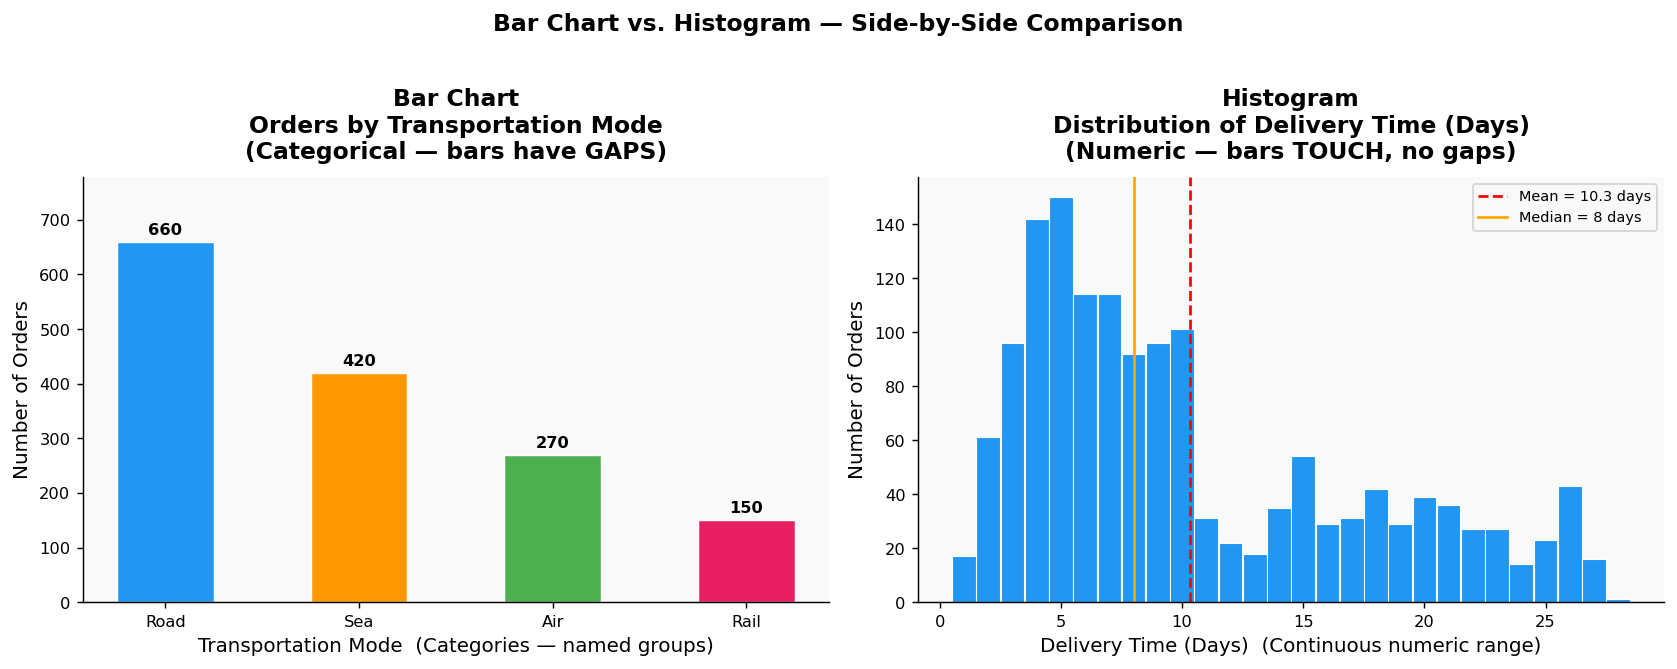

Chart saved → chart_3_bar_vs_histogram.png


In [98]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── LEFT: Bar Chart (categorical) ────────────────────────────────────────────
mode_orders = df["Transportation Mode"].value_counts().reset_index()
mode_orders.columns = ["Mode", "Orders"]
mode_orders = mode_orders.sort_values("Orders", ascending=False)

axes[0].bar(mode_orders["Mode"], mode_orders["Orders"],
            color=PALETTE[:4], width=0.5, edgecolor="white", linewidth=0.8)
for bar, val in zip(axes[0].patches, mode_orders["Orders"]):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 8, str(val),
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_title("Bar Chart\nOrders by Transportation Mode\n(Categorical — bars have GAPS)", pad=10)
axes[0].set_xlabel("Transportation Mode  (Categories — named groups)")
axes[0].set_ylabel("Number of Orders")
axes[0].set_ylim(0, mode_orders["Orders"].max() * 1.18)

# ── RIGHT: Histogram (numeric) ───────────────────────────────────────────────
max_d = int(df["Delivery Time Days"].max())
axes[1].hist(df["Delivery Time Days"], bins=range(1, max_d + 2), align="left", color="#2196F3",
             edgecolor="white", linewidth=0.6, rwidth=0.98)
axes[1].set_title("Histogram\nDistribution of Delivery Time (Days)\n(Numeric — bars TOUCH, no gaps)", pad=10)
axes[1].set_xlabel("Delivery Time (Days)  (Continuous numeric range)")
axes[1].set_ylabel("Number of Orders")

# Annotate mean and median
mean_val   = df["Delivery Time Days"].mean()
median_val = df["Delivery Time Days"].median()
axes[1].axvline(mean_val,   color="red",    linestyle="--", linewidth=1.5, label=f"Mean = {mean_val:.1f} days")
axes[1].axvline(median_val, color="orange", linestyle="-",  linewidth=1.5, label=f"Median = {median_val:.0f} days")
axes[1].legend(fontsize=8)

plt.suptitle("Bar Chart vs. Histogram — Side-by-Side Comparison",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("chart_3_bar_vs_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_3_bar_vs_histogram.png")

#### 📌 Interpretation

**Bar Chart (left):**
- Each bar represents one named group (**Road 660, Sea 420, Air 270, Rail 150**). They are **separate categories**.
- Visible gaps separate the bars because there is no numeric continuity between "Road" and "Sea".
- You can reorder the bars (e.g., tallest first, as shown here, or alphabetically) without breaking the meaning.

**Histogram (right):**
- The x-axis is a **continuous numeric range** (1 day to 28 days) — measured duration, not category names.
- Bars **touch each other** with no gaps because every day between 1 and 28 is part of one continuous scale.
- You **cannot** reorder the bars — 1 day must come before 2 days.
- The shape is **right-skewed**: most deliveries cluster between 4 and 10 days (driven by Road and Air), while Sea shipments create a long tail out to 28 days.
- The **Mean (10.3 days) > Median (8 days)** because those slow Sea shipments pull the average upward.

> **Core insight:** Use a **Bar Chart** to compare distinct named groups.
> Use a **Histogram** to inspect the shape, spread, and skew of a continuous numeric variable.

---
## 🥧 Section 4 — Pie Charts

### What is a Pie Chart?
A **Pie Chart** is a circle divided into slices. Each slice represents one category's
**share of the total (percentage)**. The bigger the slice, the larger the share.

**When to use it:** When you want to show **parts of a whole** — where all slices add up to 100%.
Best with **few categories (≤ 6)** so the slices are easy to read.

> **Important:** Pie charts answer the question *"What fraction of the total does each part represent?"*
> They should NOT be used for comparing absolute values — use a Bar Chart for that.

### 4.1 Standard Pie Chart
**Definition:** The classic circular chart. Each slice size is proportional to its category's share.

**Why Standard Pie?** When there are very few categories (here: 4 Order Statuses) and
you want to show the **dominant slice at a glance**. The audience can immediately see that
one status overwhelmingly dominates the others.

**Data used:** Share of orders by **Order Status** (Delivered / In Transit / Delayed / Cancelled)

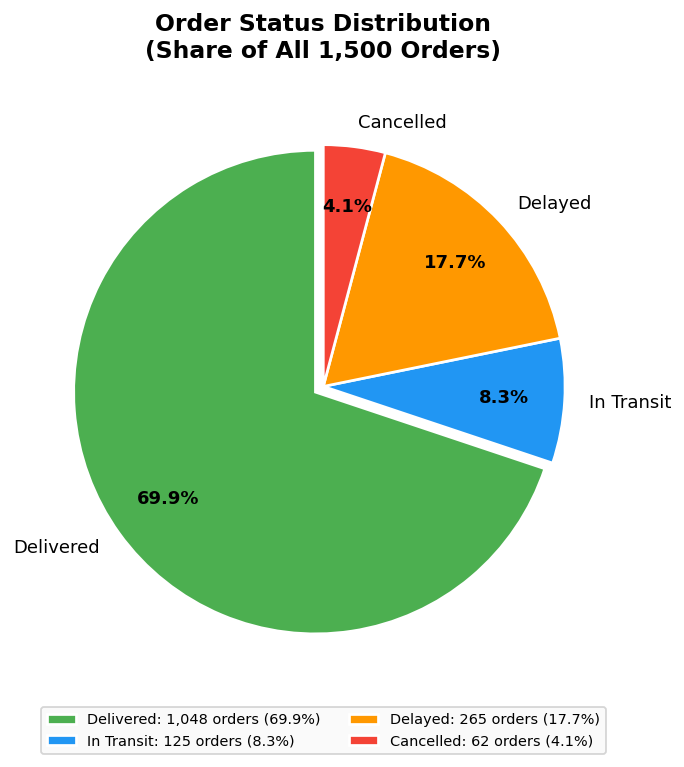

Chart saved → chart_4_1_standard_pie.png


In [99]:
# ── Aggregate ────────────────────────────────────────────────────────────────
status_counts = df["Order Status"].value_counts()
status_order  = ["Delivered", "In Transit", "Delayed", "Cancelled"]
status_counts = status_counts.reindex(status_order)
status_colors_pie = ["#4CAF50", "#2196F3", "#FF9800", "#F44336"]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    colors=status_colors_pie,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    explode=[0.04, 0, 0, 0],   # slightly explode the dominant slice
)
for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight("bold")
for text in texts:
    text.set_fontsize(10)

ax.set_title("Order Status Distribution\n(Share of All 1,500 Orders)", pad=15)

# Legend with absolute counts
legend_labels = [f"{s}: {c:,} orders ({c/status_counts.sum()*100:.1f}%)"
                 for s, c in zip(status_counts.index, status_counts.values)]
ax.legend(wedges, legend_labels, loc="lower center",
          bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig("chart_4_1_standard_pie.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_1_standard_pie.png")

#### 📌 Interpretation
- **Delivered (69.9%)** is the largest slice — **1,048** out of 1,500 orders reached customers.
- **Delayed (17.7%)** is surprisingly large (**265 orders**) — nearly **1 in 5 orders** is delayed (and as Chart 2.5 showed, **Sea freight causes most of those delays**).
- **In Transit (8.3%, 125 orders)** and **Cancelled (4.1%, 62 orders)** form the remaining share.
- **Why this chart?** With only 4 categories adding up to 100%, a standard pie chart immediately highlights
  both our overall delivery rate (~70%) and the sizable delay problem (~18%).

### 4.2 Donut Chart
**Definition:** A Donut chart is a Pie chart with a **hole cut out of the center**.
The slices show the same proportional information, but the empty center can hold a
key number or label — making it both readable and informative.

**Why Donut?** Same part-to-whole purpose as a standard pie, but the center space displays
a headline KPI (total orders). The ring shape also focuses the eye on arc length, making
unequal slices stand out cleanly.

**Data used:** Share of orders by **Transportation Mode** with total orders in the center.

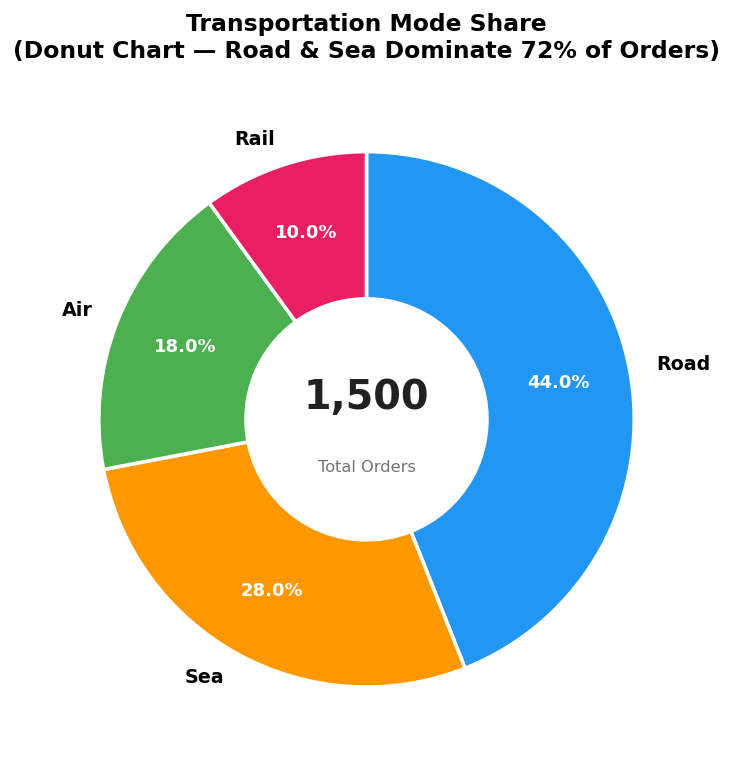

Chart saved → chart_4_2_donut.png


In [100]:
# ── Aggregate ────────────────────────────────────────────────────────────────
mode_share   = df["Transportation Mode"].value_counts().sort_values(ascending=False)
total_orders = mode_share.sum()
mode_colors  = ["#2196F3", "#FF9800", "#4CAF50", "#E91E63"]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    mode_share.values,
    labels=mode_share.index,
    colors=mode_colors,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.73,
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.55},  # width < 1 = donut
)
for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight("bold")
    text.set_color("white")
for text in texts:
    text.set_fontsize(10.5)
    text.set_fontweight("bold")

# Center label (what makes a donut unique)
ax.text(0, 0.08, f"{total_orders:,}", ha="center", va="center",
        fontsize=22, fontweight="bold", color="#212121")
ax.text(0, -0.18, "Total Orders", ha="center", va="center",
        fontsize=9, color="#757575")

ax.set_title("Transportation Mode Share\n(Donut Chart — Road & Sea Dominate 72% of Orders)", pad=15)
plt.tight_layout()
plt.savefig("chart_4_2_donut.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_2_donut.png")

#### 📌 Interpretation
- **Road dominates at 44.0% (660 orders)** — nearly half of all shipments travel by road freight.
- **Sea is second at 28.0% (420 orders)** — together, Road and Sea handle **72% of all orders**.
- **Air (18.0%, 270 orders)** is used selectively for faster deliveries, while **Rail (10.0%, 150 orders)** is the smallest channel.
- **Why this chart vs. standard pie?** With clear, unequal slice sizes (`44% → 28% → 18% → 10%`),
  the Donut ring makes the contrast obvious while using the hollow center to highlight **1,500 Total Orders**.

### 4.3 Sunburst Chart
**Definition:** A Sunburst chart is a **multi-level pie chart**. The inner ring shows the top-level
categories; the outer ring(s) show sub-categories inside each slice. It is used to visualise
**hierarchical (parent-child) data** in one circular view.

**Why Sunburst?** When your data has two or more levels of grouping (like Category → Products)
and you want to see both the parent size and the child breakdown at once.
A regular pie can only show one level.

**Data used:** **Product Category** (inner ring, 5 categories) → **Product Name** (outer ring, 25 products)
coloured by Total **Profit** so slice size = number of orders and colour = how profitable each product is.

In [101]:
# ── Aggregate ────────────────────────────────────────────────────────────────
sun = (
    df.groupby(["Product Category", "Product Name"])
    .agg(Orders=("Order ID", "count"), Profit=("Profit", "sum"))
    .reset_index()
)

fig = px.sunburst(
    sun,
    path=["Product Category", "Product Name"],
    values="Orders",
    color="Profit",
    color_continuous_scale="RdYlGn",
    color_continuous_midpoint=sun["Profit"].median(),
    title="Product Hierarchy: Category → Product Name<br>"
          "<sup>Slice size = number of orders &nbsp;|&nbsp; Colour = total profit (green = high)</sup>",
)
fig.update_layout(
    height=580,
    margin=dict(t=90, b=20, l=20, r=20),
    coloraxis_colorbar=dict(title="Profit (USD)", tickformat="$,.0f"),
    font=dict(family="Arial", size=12),
)
fig.show()

#### 📌 Interpretation
- The **inner ring** shows the 5 Product Categories sized by order count (`FMCG` 328, `Electronics` 310, `Furniture` 304, `Healthcare` 289, `Apparel` 269).
- The **outer ring** splits each category into its 5 individual products (e.g., `Bluetooth Speaker`, `Wireless Earbuds`, `Smart Watch`, `Router`, `Power Bank` inside Electronics).
- **Colour reveals the key business insight:** **FMCG** has the largest order slice yet appears **red/orange** (lowest profit, ~\$70K–\$103K per product), whereas **Electronics** is **deep green** (highest profit, ~\$530K–\$719K per product).
- **Why this chart?** A standard pie chart can only display one level (Category OR Product).
  A Sunburst shows the parent-child hierarchy AND compares profit performance across all 25 products at once.

### 4.4 Polar Area Pie Chart
**Definition:** A Polar Area chart is similar to a standard pie chart but with one key difference:
all slices have the **same angle** (they span equal degrees). Instead, the **radius (distance from center)**
varies — a bigger radius means a bigger value. It combines the circular layout of a pie chart
with the length-based encoding of a bar chart.

**Why Polar Area?** When you have cyclic categories (like the 12 months of a year) and
want to show changing magnitudes in a circular shape. The audience immediately spots
which months "reach outward" (high profit) and which pull inward (low profit).

**Data used:** Monthly **Total Profit** across all 12 months (combining 2024 and 2025 data)

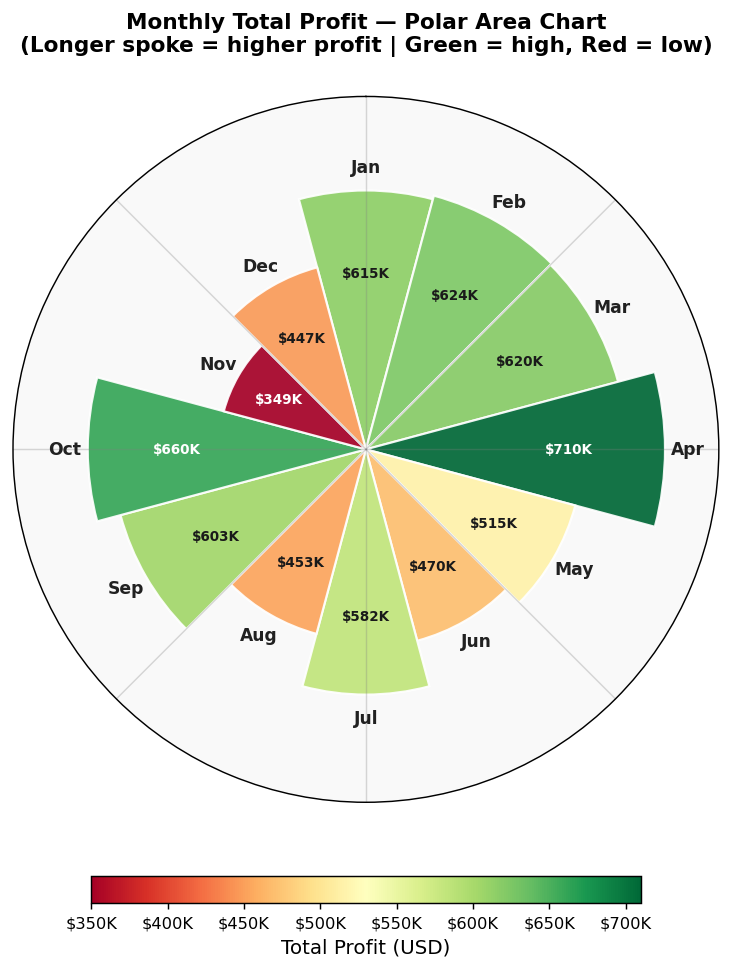

Chart saved → chart_4_4_polar_area.png


In [102]:
# ── Aggregate ────────────────────────────────────────────────────────────────
month_profit = (
    df.groupby("Order Month")["Profit"]
    .sum()
    .reset_index()
)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_profit["Month Name"] = month_profit["Order Month"].apply(lambda x: month_names[x-1])

# ── Build Polar Area using matplotlib polar projection ───────────────────────
N = 12
angles   = np.linspace(0, 2 * np.pi, N, endpoint=False)
values   = month_profit["Profit"].values
v_min, v_max = values.min(), values.max()
norm_vals = (values - v_min) / (v_max - v_min)      # match colorbar scale 0..1
colors_polar = plt.cm.RdYlGn(norm_vals)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_zero_location("N")     # 12 o'clock = January
ax.set_theta_direction(-1)          # clockwise

width = 2 * np.pi / N               # equal angular width for each slice
ax.bar(angles, values, width=width, bottom=0,
       color=colors_polar, edgecolor="white", linewidth=1.2, alpha=0.92)

# Month labels & value labels with automatic dark/light contrast
for angle, label, val, nv in zip(angles, month_names, values, norm_vals):
    ax.text(angle, val + 55_000, label,
            ha="center", va="center", fontsize=9.5, fontweight="bold", color="#212121")
    txt_color = "#1a1a1a" if 0.22 <= nv <= 0.78 else "white"
    ax.text(angle, val * 0.68, f"${val/1e3:.0f}K",
            ha="center", va="center", fontsize=7.5, color=txt_color, fontweight="bold")

ax.set_yticks([])                   # hide radial grid labels
ax.set_xticklabels([])              # hide default angle labels (we added our own)
ax.set_ylim(0, v_max * 1.18)
ax.set_title("Monthly Total Profit — Polar Area Chart\n"
             "(Longer spoke = higher profit | Green = high, Red = low)",
             pad=25, fontsize=12, fontweight="bold")
ax.grid(color="grey", alpha=0.3)

# Colour bar legend matching the exact slice colours
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(v_min, v_max))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    shrink=0.55, pad=0.08, label="Total Profit (USD)")
cbar.ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))

plt.tight_layout()
plt.savefig("chart_4_4_polar_area.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_4_polar_area.png")

#### 📌 Interpretation
- **April (\$710K)** stretches farthest outward in deep green — the highest-profit month.
- **October (\$660K)** and **February (\$624K)** / **March (\$620K)** are strong runners-up.
- **November (\$349K)** shrinks to the shortest red spoke (about half of April), followed by **December (\$447K)** and **August (\$453K)**.
- **Why this chart?** Months form a continuous 12-month cycle (Dec wraps back to Jan).
  Giving every month an equal angle while varying the radius lets the audience compare all 12 months
  in one circular glance — unlike a standard pie chart, where tiny angle differences between 12 slices are hard to judge.

---
## ✅ Section 5 — Conclusion

### Key Takeaway: Choosing the Right Chart
The goal of data visualization is not to draw "any chart" — it is to **pick the right chart
for the right data and the right question**. Here is a quick summary of what we learned:

| Chart Type | Use When | Example in This Notebook |
|---|---|---|
| **Vertical Bar** | Few short-named categories, compare values | Profit by Product Category (`Electronics $3.00M` leads) |
| **Horizontal Bar** | Many or long-named categories | Orders by Customer Country (27 countries; US `180` leads) |
| **Grouped Bar** | Two categorical dimensions, side-by-side comparison | Twenty grouped comparisons, including regional delivery, profit, costs, inventory, order volume, and status |
| **Stacked Bar** | Show totals AND breakdown at once | Profit by Region stacked by Category (`$2.30M` NA → `$0.50M` Africa) |
| **100% Stacked Bar** | Compare proportions, totals don't matter | Order Status by Mode (`Sea 45% Delayed` vs `Air 1.1%`) |
| **Waterfall** | Show step-by-step change between two values | 2024 → 2025 Profit Bridge (`$2.60M → $4.05M`) |
| **Histogram** | Understand the distribution/shape of one numeric variable | Delivery Time (`1–28 days`, Mean `10.3`, Median `8`) |
| **Standard Pie** | Show parts of a whole, few slices (≤ 6) | Order Status split (`69.9% Delivered`, `17.7% Delayed`) |
| **Donut** | Same as pie, but center holds a key number | Transport Mode share (`Road 44%`, `Sea 28%`, `Air 18%`, `Rail 10%`) |
| **Sunburst** | Multi-level hierarchy (parent → child) | Category → Product Name |
| **Polar Area** | Cyclic categories (months/seasons) + magnitude difference | Monthly Profit (`Apr $710K` vs `Nov $349K`) |

---

### Why Answer "Why This Chart?"
> *A chart without a reason is just decoration.*

Throughout this notebook, every chart answers three questions:
1. **What is this chart?** — the definition
2. **What does it show?** — the data interpretation
3. **Why this chart for this data?** — the justification

That is the core skill of data visualization: not drawing charts, but **choosing the right one**.

---
*Dataset: SupplyChain Dataset.csv — 1,500 orders, 24 columns, 2024–2025*
*Tools: Python 3 · pandas · NumPy · Matplotlib · Seaborn · Plotly*